# Riding the Fixed-Point Curve: Image Classification in the Continuous Thought Machine
### Reproduction notebook · ImageNet

*Companion notebook to the paper* **"Riding the Fixed-Point Curve: Image Classification in the Continuous
Thought Machine"** (T. Hannagan, NeurReps 2026, Extended Abstract Track, non-archival; extended version on arXiv: [arxiv.org/abs/2610.19220](https://arxiv.org/abs/2610.19220)).
It loads the official pretrained ImageNet CTM (**no training**) and reproduces every ImageNet figure, table and
number of the **extended (arXiv) version** of the paper (v2), and nothing else, **on the full ImageNet validation set (all 1000 classes)**. This is a separate project from the 120-class run behind arXiv v1: it writes only to `MyDrive/ctm_project_imagenet1000`. The MNIST / CIFAR rows of Table 2 and
the numbers of §8 live in the companion notebook `ctm_reproduce_mnist_cifar.ipynb`.


### One tick of the CTM

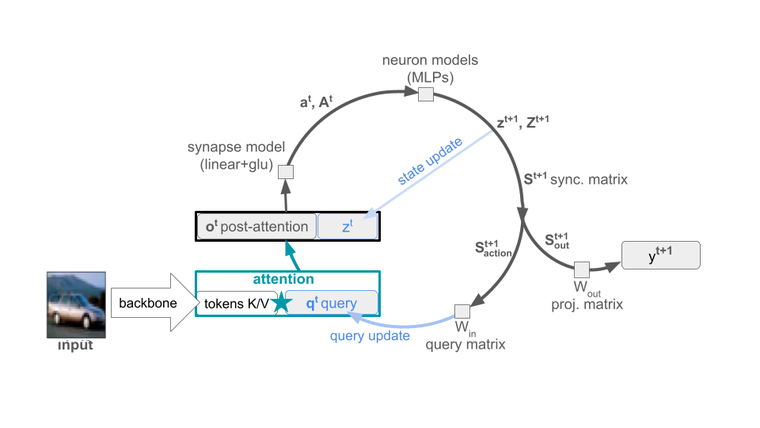

The image is read **once**. Everything after that is the loop: the state queries the token bank, the
synapse and neuron models produce the next state, the synchronization matrix accumulates it, and the
readout is taken from a fixed slice of that matrix. The paper is about what goes round this loop.

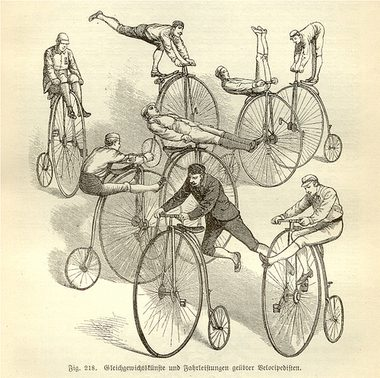

Right figure: *Gleichgewichtskünste und Fahrleistungen geübter Velocipedisten* — balancing feats of
practised velocipedists. Offered without further justification, except that a rider who stays upright
by leaning perpetually into a balance point that has already moved on is not the worst picture of a
state that trails its own attractor, one tick late, for fifty ticks together.

<br clear="all"/>

### What this notebook reproduces

Figure and table numbers are those of the **extended (arXiv) version**. Every analysis cell carries a tag such as
**[3.2]** in its heading: the number before the dot is the paper section (A–D for the appendices), the number
after it the cell's position within that section. Each figure is written under a file name that starts with its
paper number.

**Figures and tables**

| Paper | Title | Cell | Output |
|---|---|---|---|
| Figure 1 | One tick of the CTM | — | `fig1_architecture.png` (drawn by hand, provided with the paper) |
| Figure 2 | Attracting but non-normal, and one tick late | [3.3] (uses [3.1]) | `fig2_spectrum_imagenet.png` |
| Figure 3 | The fixed-point curve | [3.6] | `fig3_fixed_point_curve_imagenet.png` |
| Figure 4 | The attention scan is a shared schedule | [4.3] | `fig4_attention_scan_imagenet.png` |
| Figure 5 | The traveling wave is the moving fixed point | [5.3] (uses [5.1]) | `fig5_traveling_wave_imagenet.png` |
| Figure 6 | What sharpens the prediction | [7.3] | `fig6_memory_controls_imagenet.png` |
| Figure 7 | The tick map is a feed-forward cascade in its Schur basis | [B.3] (uses [5.5], image 0) | `fig7_schur_imagenet.png` |
| Figure 8 | The shared schedule | [C.2] (uses [C.1]) | `fig8_shared_schedule_imagenet.png` |
| Table 1 | Query/attention ablations | [4.1] | printed |
| Table 2 | Cross-model comparison, ImageNet row | [8.1] (reads [3.1], [4.1]) | printed; MNIST and CIFAR rows in the companion notebook |
| Table 3 | Balanced-amplification descriptors | [B.2], [B.2b] (uses [B.1]) | printed |
| Table 4 | Headline numbers with $n$ and 95% intervals | [D.1] | printed |

**Sample sizes.** Every analysis takes the first $n$ images of one shuffled subsample holding one validation image
per class, so $n$ images are $n$ classes and the samples are nested. All sizes live in one `SAMPLES` table in the
configuration cell, with two presets: `PRESET = 'PAPER'` (the sizes below) and `PRESET = 'FAST'` (about a tenth,
to check the notebook end to end in well under an hour). Cache keys include $n$, so the presets never mix.

| Cell | Analysis | $n$ (PAPER) |
|---|---|---|
| [3.1] | spectrum $\rho$, $\sigma_{\max}$ at $z^*$ | 256 images × 12 ticks (pairs where the fixed point converges) |
| [3.2] | other basins | 64 images × 3 ticks × 18 starts |
| [3.3] | Figure 2b–c, lag scan | 128 |
| [3.4] | what training adds | 64 per model |
| [3.5] | lag against the contraction rate | 128 × 12 ticks |
| [4.1], [D.1] | Table 1 ablations | 1000 |
| [4.2], [C.1], [C.2] | factorization, prediction, shared schedule | 1000 (600 fit / 400 held out) |
| [4.4] | intervening on the schedule: effect on the fixed-point curve, overall and after removing the shared curve | 96 × 12 ticks |
| [5.4] | wave orderings and wave–schedule coupling | 128 |
| [5.5] | cascade account | 16 |
| [6.1] | class identity | 50 classes × 50 images (own subset) |
| [7.1] | entropy curve / decomposition | 1000 / 256 |
| [7.2] | state step vs entropy gradient | 256 |
| [7.3] | Figure 6 memory controls | 512 |
| [A.1] | finite-difference check | 32 fixed points |
| [B.1], [B.2] | materialized Jacobians, Table 3 | 20 images × 3 ticks |
| [B.2b] | the same for the untrained CTM (Table 3) | 20 images × 3 ticks |
| [C.3] | query's direct effect | 256 |

Figures 3, 4, 5 and 7 show one or two images and are illustrations; every number quoted in the text comes from the
population cells above, as a median with a bootstrap 95% interval.

**Structure.** Part 1 sets up the environment, checkpoint and data; Part 2 defines the shared helpers; Part 3
follows the paper section by section, then its appendices. Heavy cells cache their results under `BASE/cache`
(set `RECOMPUTE = True` to redo them); figures are written to `BASE/figures_imagenet`.

**How to cite.**

```bibtex
@misc{hannagan2026riding,
  title         = {Riding the Fixed-Point Curve: Image Classification in the Continuous Thought Machine},
  author        = {Hannagan, Thomas},
  year          = {2026},
  eprint        = {2610.19220},
  archivePrefix = {arXiv},
  primaryClass  = {cs.LG},
  note          = {NeurIPS 2026 Workshop on Symmetry and Geometry in Neural Representations (NeurReps)}
}
```


In [ ]:
!pip -q install -U kaggle   # recent client (accepts KAGGLE_API_TOKEN)
import os
# Kaggle is only needed the first time, to download the ImageNet validation set (later runs read it from Drive).
# Store your token as a Colab secret named KAGGLE_API_TOKEN (key icon in the left sidebar), or put
# kaggle.json in ~/.kaggle. Never paste a token into the notebook itself.
try:
    from google.colab import userdata
    os.environ.setdefault('KAGGLE_API_TOKEN', userdata.get('KAGGLE_API_TOKEN') or '')
except Exception:
    pass
print('Kaggle token found' if os.environ.get('KAGGLE_API_TOKEN') or os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json'))
      else 'No Kaggle token: fine if the validation set is already on Drive; needed for the first download.')


# Part 1 · Setup

## Configuration

In [ ]:
# ---- what to run -------------------------------------------------------------------------------
# There is a single official checkpoint, so the 3-seed aggregation used for the small models collapses to one
# model; dispersion is reported ACROSS SAMPLES instead. Nothing here trains.
# Heavy cells cache their results to Drive. Set True to force recomputation.
RECOMPUTE = False

RUN_SMOKE_TEST  = True    # run the goldfish image through the model and check predicted class == 1

# ---- checkpoint & data storage (Drive on Colab; local fallback everywhere else) ----------------
USE_DRIVE = True
# A SEPARATE project folder for the full 1000-class validation set. Everything this notebook writes
# (checkpoint, data bundles, caches, figures) goes under it, with the same subfolders as the earlier
# 120-class project in MyDrive/ctm_project, which is never read or written.
DRIVE_DIR = '/content/drive/MyDrive/ctm_project_imagenet1000'   # <-- your folder
LOCAL_DIR = './ctm_project_imagenet1000'                        # fallback when Drive is unavailable

# ---- ImageNet val subsample from KAGGLE, stored on Drive ---------------------------------------
# We pull an ImageNet val set from Kaggle and keep only an aggressive subsample of preprocessed
# tensors. Use a dataset laid out as  val/<wnid>/*.JPEG  (torchvision ImageFolder layout): its
# class order is sorted-wnid = exactly the CTM's output index order, so labels align by
# construction. The cell asserts the class set matches, so a wrong dataset fails loudly.
#
# Kaggle auth (either works):
#   - set KAGGLE_USERNAME and KAGGLE_KEY below (or as env vars), or
#   - upload your kaggle.json to the session (Kaggle -> Account -> Create New API Token).
# Common val datasets in wnid-folder layout (pick one you can access, verify the slug on Kaggle):
#   'titericz/imagenet1k-val' (used here; any copy with 1000 class folders x 50 images works)
KAGGLE_DATASET  = 'titericz/imagenet1k-val'   # ImageNet-1k validation set, 1000 class folders x 50 images
KAGGLE_USERNAME = ''      # <-- or leave blank and rely on kaggle.json / env vars
KAGGLE_KEY      = ''
VAL_PER_CLASS   = 1       # images per class: 1 -> 1000 images, one from every class
VAL_N_CLASSES   = 1000    # how many classes to cover (1000 = all). Lower for a first tiny pass.
VAL_MAX_TOTAL   = 10000    # hard cap on stored images, whichever binds first
VAL_MIN_ACC     = 0.40    # sanity floor: subsample top-1 must clear this or labels are misaligned

# ---- conventions (unchanged from the paper) ----------------------------------------------------
DECISION_MODE   = 'most_certain_tick'   # t_dec = argmax_t certainty  (CTM authors' own convention)
TRUNCATE_WINDOW = True

# ---- sample sizes: ONE table, two presets --------------------------------------------------------
# Every analysis takes the first n images of the shuffled 1000-image subsample (one image per class,
# so n images = n classes). Cache keys include n, so the two presets never mix.
#   'PAPER' : the sizes used for the paper (~4-6 h on an A100 beyond what is already cached)
#   'FAST'  : about a tenth of that, to check the whole notebook end to end in well under an hour
PRESET = 'PAPER'
_SIZES = {           # PAPER  FAST
    'spectrum':      (256,   16),   # [3.1]  rho, sigma_max at z* (x 12 ticks)
    'basin':         ( 64,    8),   # [3.2]  restarts from distant states (x 3 ticks x 6 starts x 3 kinds)
    'lag_scan':      (128,   16),   # [3.3]  Figure 2b-c, lag scan
    'null':          ( 64,    8),   # [3.4]  trained vs random core vs untrained (per model)
    'lag_rc':        (128,   16),   # [3.5]  lag against the contraction rate (x 12 ticks)
    'ablate':        (1000, 128),   # [4.1], [D.1] Table 1 ablations
    'sched':         (1000, 128),   # [4.2], [C.1], [C.2] factorization / prediction (60% fit, 40% held out)
    'causal':        ( 96,   16),   # [4.4]  does the schedule move the fixed-point curve?
    'wave':          (128,   16),   # [5.4]  wave orderings and wave-schedule coupling
    'cascade':       ( 16,    2),   # [5.5]  cascade account (one Schur form per image)
    'ci_classes':    ( 50,   20),   # [6.1]  class identity: classes ...
    'ci_per_class':  ( 50,   25),   #        ... x images per class (its own subset of the full val set)
    'entropy_curve': (1000, 128),   # [7.1]  entropy curve, median decision tick
    'decomp':        (256,   16),   # [7.1]  memory/state decomposition and increments
    'grad':          (256,   16),   # [7.2]  state step vs entropy gradient
    'rc3':           (512,   64),   # [7.3]  Figure 6 memory controls
    'fd':            ( 32,    4),   # [A.1]  finite-difference check (fixed points)
    'schur':         ( 20,    3),   # [B.1], [B.2] materialized Jacobians (x 3 ticks)
    'qeffect':       (256,   16),   # [C.3]  the query's direct one-step effect
}
SAMPLES = {k: v[0 if PRESET == 'PAPER' else 1] for k, v in _SIZES.items()}
N_CONTRACT = SAMPLES['spectrum']
print(f'PRESET = {PRESET}: ' + ', '.join(f'{k} {v}' for k, v in SAMPLES.items()))

print(f'USE_DRIVE={USE_DRIVE}  DRIVE_DIR={DRIVE_DIR!r}')
print(f'kaggle dataset: {KAGGLE_DATASET!r}')
print(f'val subsample: {VAL_PER_CLASS}/class x {VAL_N_CLASSES} classes, cap {VAL_MAX_TOTAL}')

# Figure resolution for every saved PNG.
FIG_DPI = 300
SPEC_BS         = 16      # image batch for the batched spectral cell [3.1] (lower if OOM)

## Environment — clone the official repo, install helpers

On Colab this clones the CTM repo (for `models.ctm`) and installs `gdown` (checkpoint) and
`datasets` (val subsample). Off Colab it assumes the repo is importable and the packages present.

In [ ]:
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not os.path.exists('continuous-thought-machines'):
        os.system('git clone -q https://github.com/SakanaAI/continuous-thought-machines.git')
    sys.path.append('continuous-thought-machines')
    os.system('pip -q install gdown datasets mediapy')
else:
    # expects the repo on PYTHONPATH already
    for p in ('.', './continuous-thought-machines', '..'):
        if os.path.exists(os.path.join(p, 'models', 'ctm.py')) and p not in sys.path:
            sys.path.append(p)
print('IN_COLAB =', IN_COLAB)

In [ ]:
import math, time, json, re
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import transforms
from tqdm.auto import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert device.type == 'cuda', 'Enable a GPU (Runtime -> Change runtime type -> T4).'
print('Device:', torch.cuda.get_device_name(0))

# --- storage dirs (Drive if mounted, else local) ------------------------------------------------
if USE_DRIVE and IN_COLAB:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        BASE = DRIVE_DIR
    except Exception as e:
        print('Drive mount failed, falling back to local:', e); BASE = LOCAL_DIR
else:
    BASE = LOCAL_DIR
CKPT_DIR = os.path.join(BASE, 'imagenet_ckpt')
VAL_DIR  = os.path.join(BASE, 'imagenet_val_sub')
FIG_DIR  = os.path.join(BASE, 'figures_imagenet')
_new_project = not os.path.isdir(BASE)
for d in (CKPT_DIR, VAL_DIR, FIG_DIR): os.makedirs(d, exist_ok=True)
assert os.path.basename(os.path.normpath(BASE)) != 'ctm_project', 'refusing to write into the 120-class project folder'
print(('created a NEW project folder: ' if _new_project else 'project folder: ') + BASE)
def fig_path(fname): return os.path.join(FIG_DIR, fname)
print('BASE =', BASE)

# ---- disk cache for the slow cells -------------------------------------------------
# Heavy results (the Jacobian sweeps) are stored under BASE/cache and reloaded unless
# RECOMPUTE is True. Delete a file there to recompute just that one.
CACHE_DIR = os.path.join(BASE, 'cache'); os.makedirs(CACHE_DIR, exist_ok=True)

def cached(name, compute):
    """Return compute(), memoised on disk under CACHE_DIR/<name>.pt."""
    path = os.path.join(CACHE_DIR, f'{name}{globals().get("VAL_TAG","")}.pt')  # val-aware
    if not RECOMPUTE and os.path.exists(path):
        print(f'[cache] {name}: loaded (set RECOMPUTE=True to redo)')
        return torch.load(path, weights_only=False)
    result = compute()
    torch.save(result, path); print(f'[cache] {name}: computed and saved')
    return result

def boot_ci(x, stat=np.median, nboot=2000, seed=0):
    x=np.asarray(x,float); x=x[~np.isnan(x)]; r=np.random.default_rng(seed)
    b=np.array([stat(r.choice(x,len(x),replace=True)) for _ in range(nboot)])
    return float(stat(x)), round(float(np.quantile(b,0.025)),3), round(float(np.quantile(b,0.975)),3)
def verdict(ok): return 'HOLDS' if ok else 'SHIFTED -- inspect'

## Download and load the official ImageNet checkpoint

Pulled once from the authors' Google Drive and cached under `CKPT_DIR`. The model is rebuilt from
`checkpoint['args']` exactly as in the official `02_inference.ipynb`, then set to `eval()`. **No
training.**

In [ ]:
from models.ctm import ContinuousThoughtMachine as CTM
import glob, zipfile, shutil

# The checkpoint is re-downloadable, so unlike trained models it does NOT need to live on Drive.
# Multi-GB reads/writes through Drive's FUSE layer can truncate, which corrupts the .pt (a .pt is
# itself a zip; "failed finding central directory" == truncated). So we STAGE it on local Colab
# disk and load from there. A Drive copy of imagenet.zip is reused only if it is a valid zip.
GDRIVE_ID   = '1Lr_3RZU9X9SS8lBhAhECBiSZDKfKhDkJ'
STAGE_DIR   = '/content/imagenet_ckpt_local'      # fast local disk, wiped on runtime reset
os.makedirs(STAGE_DIR, exist_ok=True)

def _valid_ckpt(p):
    # a good torch .pt is a valid zip with a readable central directory
    return p and os.path.exists(p) and zipfile.is_zipfile(p)

def _find_ckpt(d):
    hits = [p for p in glob.glob(os.path.join(d, '**', '*.pt'), recursive=True)
            if '__MACOSX' not in p and not os.path.basename(p).startswith('._')]
    hits.sort(key=lambda p: ('imagenet' not in os.path.basename(p).lower(), len(p)))
    return hits[0] if hits else None

def _unzip_and_find(zip_path, dest):
    assert zipfile.is_zipfile(zip_path), f'{zip_path} is not a valid zip (truncated download).'
    with zipfile.ZipFile(zip_path) as zf: zf.extractall(dest)
    return _find_ckpt(dest)

CKPT_PATH = _find_ckpt(STAGE_DIR)                 # 1) already staged locally and valid?
if not _valid_ckpt(CKPT_PATH):
    CKPT_PATH = None
    local_zip = os.path.join(STAGE_DIR, 'imagenet.zip')
    drive_zip = os.path.join(CKPT_DIR, 'imagenet.zip')
    # 2) reuse a VALID Drive zip (avoids re-download); else re-download fresh to local
    if os.path.exists(drive_zip) and zipfile.is_zipfile(drive_zip):
        print('reusing valid imagenet.zip from Drive'); src_zip = drive_zip
    else:
        import gdown
        if os.path.exists(local_zip): os.remove(local_zip)
        print('downloading checkpoint zip to local disk...')
        gdown.download(f'https://drive.google.com/uc?id={GDRIVE_ID}', local_zip, quiet=False, fuzzy=True)
        with open(local_zip, 'rb') as fh: assert fh.read(2) == b'PK', (
            'Download is not a zip (Google Drive quota/permission). Open '
            f'https://drive.google.com/file/d/{GDRIVE_ID}/view in a browser to check access, retry later, '
            'or copy the file into your Drive and point CKPT_PATH at it directly.')
        src_zip = local_zip
        print('saving the checkpoint zip to Drive, so later sessions skip the download ...')
        shutil.copy(local_zip, drive_zip)
    CKPT_PATH = _unzip_and_find(src_zip, STAGE_DIR)

assert _valid_ckpt(CKPT_PATH), (
    f'No VALID .pt under {STAGE_DIR} after staging. If a Drive copy keeps corrupting, delete '
    f'{os.path.join(CKPT_DIR, "imagenet.zip")} and rerun to force a clean local download.')
print('checkpoint (local):', CKPT_PATH)

checkpoint = torch.load(CKPT_PATH, map_location=device, weights_only=False)
a = checkpoint['args']
model = CTM(
    iterations=a.iterations, d_model=a.d_model, d_input=a.d_input, heads=a.heads,
    n_synch_out=a.n_synch_out, n_synch_action=a.n_synch_action, synapse_depth=a.synapse_depth,
    memory_length=a.memory_length, deep_nlms=a.deep_memory, memory_hidden_dims=a.memory_hidden_dims,
    do_layernorm_nlm=a.do_normalisation, backbone_type=a.backbone_type,
    positional_embedding_type=a.positional_embedding_type, out_dims=a.out_dims,
    prediction_reshaper=[-1], dropout=0, neuron_select_type=a.neuron_select_type,
    n_random_pairing_self=a.n_random_pairing_self,
).to(device)
model.load_state_dict(checkpoint['model_state_dict'], strict=False)
model.eval()

T = a.iterations
D = a.d_model
print(f'CTM ImageNet: D={D}  T={T}  M={a.memory_length}  select={a.neuron_select_type}  '
      f'n_synch_out={a.n_synch_out}  out_dims={a.out_dims}')
print('readout head  output_projector =', model.output_projector)   # linear? bridge assumes y = W_out S_out

### Preprocessing and class list

Standard ImageNet eval transform. Predictions are indexed by `list(IMAGENET2012_CLASSES.values())`
— the sorted-synset order (tench=0, goldfish=1). Any val loader must yield labels in this same
order, which the HuggingFace `imagenet-1k` integer labels already do; the smoke test below verifies
it end to end.

In [ ]:
from tasks.image_classification.imagenet_classes import IMAGENET2012_CLASSES
IMAGENET_CLASS_LIST = list(IMAGENET2012_CLASSES.values())

DATASET_MEAN = [0.485, 0.456, 0.406]
DATASET_STD  = [0.229, 0.224, 0.225]
val_transform = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize(mean=DATASET_MEAN, std=DATASET_STD),
])
print('classes:', len(IMAGENET_CLASS_LIST), '| e.g. idx1 =', IMAGENET_CLASS_LIST[1])

### Smoke test — goldfish must come back as class 1

Confirms the checkpoint, the module wiring, and the label ordering *before* any compute is spent.
Uses the repo's bundled `goldfish.jpg` if present, else downloads one.

In [ ]:
if RUN_SMOKE_TEST:
    from PIL import Image
    import urllib.request
    fn = 'continuous-thought-machines/examples/goldfish.jpg'
    if not os.path.exists(fn):
        fn = 'goldfish.jpg'
        if not os.path.exists(fn):
            urllib.request.urlretrieve(
                'https://www.seahorseaquariums.com/image/cache/catalog/Categories%20-%20Freshewater/'
                'Coldwater%20Fish/Fantails/Fantail%20Goldfish-2000x2000.jpg', fn)
    img = Image.open(fn).convert('RGB')
    xt = val_transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        preds, certs, *_ = model(xt, track=False)
    tdec = certs[:, 1].argmax(-1)
    cls = preds.argmax(1)[0, tdec[0]].item()
    print(f'goldfish -> class {cls} = {IMAGENET_CLASS_LIST[cls]}  (expect 1 = goldfish)')
    assert cls == 1, 'Label ordering mismatch — do NOT trust accuracy until this passes.'
    print('smoke test passed.')

## ImageNet val subsample from Kaggle, cached on Drive

Downloads an ImageNet val set from Kaggle (`KAGGLE_DATASET`), auto-detects the class-folder layout
— either `val/<wnid>/` or numeric `00000/…/00999/` — keeps up to `VAL_PER_CLASS` per class over
`VAL_N_CLASSES` classes (capped at `VAL_MAX_TOTAL`), preprocesses to 224 tensors, and caches one
`.pt` bundle to `VAL_DIR`. Re-runs load the bundle.

**Label alignment.** For wnid folders it's guaranteed (sorted wnid == CTM index) and asserted. For
numeric folders the label is taken as the folder integer, on the standard assumption that it's the
sorted-wnid class index; this is *not* structurally provable, so the **accuracy floor**
(`VAL_MIN_ACC`) is the real check — a wrong ordering craters top-1 to ~0.001 and the cell stops.
Everything downstream only needs `val_x` (B,3,224,224) and integer `val_y`.

### The full validation set (all 1000 classes)

Downloads the Kaggle archive once, keeps it on Drive as a single file, unzips it to local disk each session, and stops unless all 1000 class folders with 50 images each are present.

In [ ]:
# The full ImageNet validation set: all 1000 classes x 50 images, unzipped on LOCAL disk.
# Earlier runs unzipped the Kaggle archive straight into Drive. That is slow and fragile: the unzip
# stopped after 127 of the 1000 class folders, and since the cell only checked that the folder was not
# empty, every later run reused the partial tree (hence 120 classes in the subsample).
# Now the archive itself is kept on Drive as ONE file (a reliable copy), unzipped each session to local
# disk, and checked: 1000 class folders with 50 images each, or the cell stops.
# The Kaggle download happens once per project: later builds copy the archive back from Drive.
import zipfile, shutil, glob, re, time
from tqdm.auto import tqdm

RAW_DIR       = '/content/imagenet_val_raw'                        # local disk, rebuilt each session
DL_DIR        = '/content/kaggle_dl'
VAL_ZIP_DRIVE = os.path.join(VAL_DIR, 'imagenet_val_kaggle.zip')   # the archive, kept on Drive
_IMG_EXT = ('.jpeg', '.jpg', '.png', '.JPEG', '.JPG', '.PNG')
_is_cls = lambda d: bool(re.match(r'^n\d{8}$', d)) or d.isdigit()

def _val_census(root):
    """Class folders under root (up to 3 levels deep) and the image count of each."""
    counts = {}
    for cur, subdirs, _ in os.walk(root):
        if cur[len(root):].count(os.sep) >= 3: subdirs[:] = []; continue
        for d in subdirs:
            if _is_cls(d) and d not in counts:
                counts[d] = sum(f.endswith(_IMG_EXT) for _, _, fs in os.walk(os.path.join(cur, d)) for f in fs)
    return counts

def _complete(counts):
    return len(counts) == 1000 and min(counts.values()) >= 50

def _ensure_full_val():
    if os.path.isdir(RAW_DIR):
        c = _val_census(RAW_DIR)
        if _complete(c): print(f'full val set ready on local disk: {len(c)} classes'); return c
    os.makedirs(DL_DIR, exist_ok=True); t0 = time.time()
    if os.path.exists(VAL_ZIP_DRIVE) and zipfile.is_zipfile(VAL_ZIP_DRIVE):
        local_zip = os.path.join(DL_DIR, 'val.zip')
        print('copying the archive from Drive to local disk ...'); shutil.copy(VAL_ZIP_DRIVE, local_zip)
    else:
        if KAGGLE_USERNAME: os.environ['KAGGLE_USERNAME'] = KAGGLE_USERNAME
        if KAGGLE_KEY:      os.environ['KAGGLE_KEY'] = KAGGLE_KEY
        print(f'downloading {KAGGLE_DATASET} from Kaggle to local disk (no unzip) ...')
        import subprocess
        r = subprocess.run(['kaggle', 'datasets', 'download', '-d', KAGGLE_DATASET, '-p', DL_DIR, '--force'],
                           capture_output=True, text=True)
        zips = glob.glob(os.path.join(DL_DIR, '*.zip'))
        if r.returncode != 0 or len(zips) != 1:
            print('kaggle stdout:', r.stdout[-2000:]); print('kaggle stderr:', r.stderr[-2000:])
            print('files in', DL_DIR, ':', os.listdir(DL_DIR))
            raise RuntimeError('Kaggle download failed: see the kaggle output above '
                               '(401/403 = token missing or revoked; 404 = wrong dataset slug).')
        local_zip = zips[0]
        print(f'  downloaded {os.path.getsize(local_zip)/1e9:.1f} GB in {time.time()-t0:.0f}s; '
              f'copying the archive to Drive for later sessions ...')
        shutil.copy(local_zip, VAL_ZIP_DRIVE)
    print(f'  archive ready ({time.time()-t0:.0f}s); unzipping to {RAW_DIR} ...')
    shutil.rmtree(RAW_DIR, ignore_errors=True)
    with zipfile.ZipFile(local_zip) as zf:
        for m in tqdm(zf.infolist(), desc='unzip', unit='file', mininterval=2):
            zf.extract(m, RAW_DIR)
    os.remove(local_zip)
    c = _val_census(RAW_DIR)
    print(f'  {len(c)} class folders, {sum(c.values())} images, min {min(c.values()) if c else 0} per class '
          f'({time.time()-t0:.0f}s)')
    assert _complete(c), ('the archive does not hold the full validation set (1000 classes x 50 images); '
                          'delete imagenet_val_kaggle.zip on Drive and rerun, or check KAGGLE_DATASET')
    return c

# Called only when a data bundle has to be BUILT (the subsample cell below, and [6.1]). Once both bundles
# exist in this project's imagenet_val_sub/ folder, later sessions never touch the archive at all.
print('full-validation helper ready (runs only if a data bundle must be built)')

### The validation subsample

`VAL_PER_CLASS` images from each of the 1000 classes, preprocessed and cached on Drive as one bundle.

In [ ]:
import re
VAL_BUNDLE = os.path.join(VAL_DIR, f'val_full_{VAL_PER_CLASS}pc_{VAL_N_CLASSES}cl_{VAL_MAX_TOTAL}.pt')   # 'full': built from all 1000 classes
IMG_EXT = ('.jpeg', '.jpg', '.png', '.JPEG', '.JPG', '.PNG')

def _is_class_dir_name(d):
    return bool(re.match(r'^n\d{8}$', d)) or d.isdigit()

def _find_val_root(base):
    # a directory whose immediate subdirs are class dirs (wnid n######## OR numeric 00000..).
    # Shallow search only (Drive/FUSE deep walks are very slow): check base, then one level down.
    def class_subdirs(p):
        try: sub = [d for d in os.listdir(p) if os.path.isdir(os.path.join(p, d))]
        except OSError: return []
        return [d for d in sub if _is_class_dir_name(d)]
    if len(class_subdirs(base)) >= 100:
        return base
    for d in sorted(os.listdir(base)):
        p = os.path.join(base, d)
        if os.path.isdir(p) and len(class_subdirs(p)) >= 100:
            return p
    raise FileNotFoundError(
        f'No class-folder tree (wnid or numeric) under {base}. Inspect the extracted layout.')

def _images_in(class_path, limit):
    # up to `limit` image files directly in class_path (else one level deeper). Stops early.
    out = []
    try: entries = sorted(os.listdir(class_path))
    except OSError: return out
    for name in entries:
        if name.endswith(IMG_EXT):
            out.append(os.path.join(class_path, name))
            if len(out) >= limit: return out
    if not out:  # nested one level deeper
        for name in entries:
            sub = os.path.join(class_path, name)
            if os.path.isdir(sub):
                for f in sorted(os.listdir(sub)):
                    if f.endswith(IMG_EXT):
                        out.append(os.path.join(sub, f))
                        if len(out) >= limit: return out
    return out

if os.path.exists(VAL_BUNDLE):
    blob = torch.load(VAL_BUNDLE, map_location='cpu')
    val_x, val_y = blob['x'], blob['y']
    print(f'loaded cached subsample: {val_x.shape[0]} images from {VAL_BUNDLE}')
else:
    from PIL import Image
    if KAGGLE_USERNAME: os.environ['KAGGLE_USERNAME'] = KAGGLE_USERNAME
    if KAGGLE_KEY:      os.environ['KAGGLE_KEY'] = KAGGLE_KEY
    _ensure_full_val()                                  # unzip + check the full val set (only when building)
    raw_dir = RAW_DIR                                   # the complete, checked tree of the cell above

    val_root = max((cur for cur, _, _ in os.walk(raw_dir) if cur[len(raw_dir):].count(os.sep) <= 3),
                   key=lambda p: sum(_is_class_dir_name(d) for d in os.listdir(p)))   # the folder holding the class folders
    class_dirs = sorted(d for d in os.listdir(val_root)
                        if os.path.isdir(os.path.join(val_root, d)) and _is_class_dir_name(d))
    wnids_model = list(IMAGENET2012_CLASSES.keys())
    print(f'val root: {val_root}  ({len(class_dirs)} class folders, e.g. {class_dirs[:3]})')

    # --- decide the label of each class folder ------------------------------------------------
    if all(re.match(r'^n\d{8}$', d) for d in class_dirs):
        # wnid layout: sorted-wnid index == CTM index. Assert the set matches, then map by name.
        assert class_dirs == wnids_model, (
            'Folder wnid order != IMAGENET2012_CLASSES order — labels would be misaligned.')
        label_of = {d: i for i, d in enumerate(wnids_model)}
        print('layout: wnid folders (labels aligned by wnid order)')
    elif all(d.isdigit() for d in class_dirs):
        # numeric layout: ASSUME folder integer is the standard sorted-wnid class index.
        # Not asserted structurally — the accuracy floor below is the real check.
        label_of = {d: int(d) for d in class_dirs}
        print('layout: numeric folders — assuming int(folder) == sorted-wnid class index '
              '(validated by the accuracy floor below)')
    else:
        raise ValueError('Class folders are neither wnids nor numeric; unsupported layout.')

    # --- build the subsample ------------------------------------------------------------------
    xs = []; ys = []; t0 = time.time()
    for d in class_dirs:
        ci = label_of[d]
        if ci >= VAL_N_CLASSES: continue
        for path in _images_in(os.path.join(val_root, d), VAL_PER_CLASS):
            try: img = Image.open(path).convert('RGB')
            except Exception: continue
            xs.append(val_transform(img)); ys.append(ci)
            if len(xs) >= VAL_MAX_TOTAL: break
        if len(xs) >= VAL_MAX_TOTAL: break
        if len(xs) % 200 == 0 and len(xs) > 0:
            print(f'  kept {len(xs)}  ({time.time()-t0:.0f}s)')
    val_x = torch.stack(xs); val_y = torch.tensor(ys, dtype=torch.long)
    assert len(torch.unique(val_y)) == min(VAL_N_CLASSES, 1000), 'subsample does not cover every class'
    torch.save({'x': val_x, 'y': val_y}, VAL_BUNDLE)
    print(f'built and cached {val_x.shape[0]} images -> {VAL_BUNDLE}')

# --- accuracy sanity: the real alignment check (still no training) ----------------------------
if val_x.shape[0] > 0:
    accs = []
    with torch.no_grad():
        for i in range(0, val_x.shape[0], 64):
            xb = val_x[i:i+64].to(device); yb = val_y[i:i+64].to(device)
            p, c, *_ = model(xb, track=False)
            td = c[:, 1].argmax(-1)
            pred = p.argmax(1)[torch.arange(xb.shape[0], device=device), td]
            accs.append((pred == yb).float().cpu())
    acc = torch.cat(accs).mean().item()
    print(f'subsample top-1 @ t_dec: {acc:.3f}  (n={val_x.shape[0]})')
    assert acc >= VAL_MIN_ACC, (
        f'top-1 {acc:.3f} < VAL_MIN_ACC {VAL_MIN_ACC}: the numeric folder order is NOT the '
        'sorted-wnid class index (or this is not ImageNet-1k val). Tell me the accuracy and a '
        'few sample filenames and I will add the correct remap.')

In [ ]:
import hashlib
_perm = torch.randperm(val_x.shape[0], generator=torch.Generator().manual_seed(0))
val_x, val_y = val_x[_perm].contiguous(), val_y[_perm].contiguous()   # shuffle: val is class-ordered
VAL_TAG = '_v' + hashlib.md5(val_y.cpu().numpy().tobytes()).hexdigest()[:6]
print(f'shuffled val: {val_x.shape[0]} images across {len(torch.unique(val_y))} classes  (cache tag {VAL_TAG})')

## Decision tick and plotting defaults

`get_decision_tick`: the tick of highest certainty, $t_{\mathrm{dec}}=\arg\max_t\mathcal{C}^t$, as in the CTM paper.

In [ ]:
def get_decision_tick(predictions, certainties):
    if DECISION_MODE == 'most_certain_tick':
        return certainties[:, 1, :].argmax(-1)
    B, Tt = predictions.shape[0], predictions.shape[-1]
    return torch.full((B,), Tt - 1, dtype=torch.long, device=predictions.device)

def legend_clear(ax, **kw):
    kw.setdefault('loc', 'upper right'); kw.setdefault('frameon', False); kw.setdefault('fontsize', 7.5)
    ax.legend(**kw)

plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
ICOL = '#2f6f9f'            # single-model colour (ImageNet)
GREY_MID, GREY_LIGHT = '#8a8a8a', '#bdbdbd'

### The tick map `f(z ; A^t)`, ported to the official model

Identical in structure to the reproduction notebook. Because `compute_synchronisation`,
`synapses`, `trace_processor`, `q_proj`, `attention`, `compute_features` all exist on the official
model with the same signatures — and `compute_synchronisation` handles `random-pairing` internally
— the bodies carry over verbatim. The **only** addition is the `decay_params` clamp that the
official `forward` applies (`clamp(·, 0, 15)`), so `r` here matches the model exactly.

As in the paper, `f(·;A^t)` freezes the context (token bank `kv`, the action-side accumulator, the
hard trace window) and treats the recurrence as a genuine map on state space. The out-side
accumulator is carried only so a `z`-only readout could be built; it never enters `f`.

In [ ]:
def _decay_r(model):
    # match forward(): r = exp(-clamp(decay_params, 0, 15))
    ra = torch.exp(-torch.clamp(model.decay_params_action, 0, 15))
    ro = torch.exp(-torch.clamp(model.decay_params_out, 0, 15))
    return ra, ro

def run_to_tick(model, x, t_stop):
    B = x.size(0)
    kv = model.compute_features(x)
    state_trace = model.start_trace.unsqueeze(0).expand(B, -1, -1).clone()
    activated_state = model.start_activated_state.unsqueeze(0).expand(B, -1).clone()
    ra, ro = _decay_r(model)
    r_action = ra.unsqueeze(0).repeat(B, 1); r_out = ro.unsqueeze(0).repeat(B, 1)
    decay_alpha_action, decay_beta_action = None, None
    _, decay_alpha_out, decay_beta_out = model.compute_synchronisation(
        activated_state, None, None, r_out, synch_type='out')
    for _ in range(t_stop):
        sync_a, decay_alpha_action, decay_beta_action = model.compute_synchronisation(
            activated_state, decay_alpha_action, decay_beta_action, r_action, synch_type='action')
        q = model.q_proj(sync_a).unsqueeze(1)
        attn_out, _ = model.attention(q, kv, kv, average_attn_weights=False, need_weights=True)
        attn_out = attn_out.squeeze(1)
        state = model.synapses(torch.cat((attn_out, activated_state), dim=-1))
        state_trace = torch.cat((state_trace[:, :, 1:], state.unsqueeze(-1)), dim=-1)
        activated_state = model.trace_processor(state_trace)
        _, decay_alpha_out, decay_beta_out = model.compute_synchronisation(
            activated_state, decay_alpha_out, decay_beta_out, r_out, synch_type='out')
    return dict(activated_state=activated_state, state_trace=state_trace, kv=kv,
                decay_alpha_action=decay_alpha_action, decay_beta_action=decay_beta_action, r_action=r_action,
                decay_alpha_out=decay_alpha_out, decay_beta_out=decay_beta_out, r_out=r_out)

def one_tick_step(model, z, frozen):
    sync_a, _, _ = model.compute_synchronisation(
        z, frozen['decay_alpha_action'], frozen['decay_beta_action'], frozen['r_action'], synch_type='action')
    q = model.q_proj(sync_a).unsqueeze(1)
    attn_out, _ = model.attention(q, frozen['kv'], frozen['kv'], average_attn_weights=False, need_weights=True)
    attn_out = attn_out.squeeze(1)
    new_state = model.synapses(torch.cat((attn_out, z), dim=-1))
    new_state_trace = torch.cat((frozen['state_trace'][:, :, 1:], new_state.unsqueeze(-1)), dim=-1)
    return model.trace_processor(new_state_trace)

@torch.no_grad()
def _self_check_tick_map(model, x_one, atol=1e-4):
    # run_to_tick(t) then one_tick_step must equal run_to_tick(t+1)'s state, proving the ported
    # map reproduces the model's own recurrence.
    t = min(5, T - 1)
    fr = run_to_tick(model, x_one, t)
    z_next_manual = one_tick_step(model, fr['activated_state'], fr)
    z_next_true = run_to_tick(model, x_one, t + 1)['activated_state']
    d = float((z_next_manual - z_next_true).abs().max())
    print(f'tick-map self-check: max|Δ| = {d:.2e}  ({"OK" if d < atol else "MISMATCH"})')
    return d < atol

### Tick-map self-check

One reconstructed step from the state at a tick must reproduce the model's own next state (§3: "a single reconstructed step reproduces the model's next state to $<10^{-6}$").

In [ ]:
# sanity: the ported tick map reproduces the model's recurrence on one real image
if val_x.shape[0] > 0:
    _self_check_tick_map(model, val_x[:1].to(device))

# Part 2 · Shared helpers

Functions used by several cells of Part 3. Nothing here is a result.

### Readout entropy, decision prediction, validation sampling

`entropy_of_z`, `decision_prediction`, `_query_at`, `_step_from_q`, `take_val`.

In [ ]:
import torch.nn.functional as F
ACTION_COL = '#3f7d3f'

def entropy_of_z(model, z, frozen_prev):
    # H_t(z): normalized entropy of the readout from z and the OUT accumulator as it stood BEFORE tick t.
    sync_o, _, _ = model.compute_synchronisation(z, frozen_prev['decay_alpha_out'],
                    frozen_prev['decay_beta_out'], frozen_prev['r_out'], synch_type='out')
    return model.compute_certainty(model.output_projector(sync_o))[..., 0]

def decision_prediction(predictions, certainties):
    t_dec = get_decision_tick(predictions, certainties)
    B = predictions.shape[0]
    pred = predictions.argmax(1)[torch.arange(B, device=predictions.device), t_dec]
    return pred, t_dec

def _query_at(model, frozen):
    sync_a, _, _ = model.compute_synchronisation(frozen['activated_state'], frozen['decay_alpha_action'],
                    frozen['decay_beta_action'], frozen['r_action'], synch_type='action')
    return model.q_proj(sync_a)

def _step_from_q(model, q, z, frozen):
    attn_out, _ = model.attention(q.unsqueeze(1), frozen['kv'], frozen['kv'],
                                  average_attn_weights=False, need_weights=True)
    attn_out = attn_out.squeeze(1)
    new_state = model.synapses(torch.cat((attn_out, z), dim=-1))
    new_trace = torch.cat((frozen['state_trace'][:, :, 1:], new_state.unsqueeze(-1)), dim=-1)
    return model.trace_processor(new_trace)

def take_val(n):
    n = min(n, val_x.shape[0]); return val_x[:n].to(device), val_y[:n].to(device)

### Fixed points and the Jacobian spectrum

`_fixed_point`, `_fp_batch` (iterate the frozen map), `_rho_batch`, `_sig_batch` (power iteration on $J$ and $J^\top J$ by autograd), and `_contract_batch`, which runs them over images and ticks.

In [ ]:
# Fixed points and the Jacobian spectrum at z*  (rho and sigma_max) -- helpers used by [3.1]-[3.5], [A.1]
# The tick map is strongly NON-NORMAL: sigma_max(J) > 1 (transient stretch along non-orthogonal
# directions) while the spectral radius rho(J) < 1 (asymptotic decay). rho governs fixed-point
# stability / Banach convergence; sigma_max is the non-normal transient. Both read AT z*(A^t), not at
# the state. The old random-secant "L" was the MEAN singular value (~sigma_F/sqrt(D)), neither.
from torch.autograd.functional import jvp as _AJVP, vjp as _AVJP

CONTRACT_TICKS = list(range(4, T, 4))   # ~12 ticks across the 50-tick rollout
RHO_ITERS = 80    # power iteration on J for the spectral radius rho(J)
SIG_ITERS = 18    # power iteration on JtJ for sigma_max(J)
FP_ITERS  = 200

def _spectral_radius(g, z, iters=RHO_ITERS, seed=0):
    # rho(J) = lim ||J^k w||^{1/k}: power-iterate J itself, average the tail per-step growth.
    z = z.detach(); torch.manual_seed(seed)
    w = torch.randn_like(z); w = w/(w.norm()+1e-12); logs=[]
    with torch.enable_grad():
        for _ in range(iters):
            _, Jw = _AJVP(g,(z,),(w,)); f=float(Jw.norm()); logs.append(math.log(f+1e-30))
            w=(Jw/(f+1e-12)).detach()
    return float(math.exp(np.mean(logs[len(logs)//2:])))

def _sigma_max(g, z, iters=SIG_ITERS, seed=0):
    z=z.detach(); torch.manual_seed(seed)
    v=torch.randn_like(z); v=v/(v.norm()+1e-12); s=0.0
    with torch.enable_grad():
        for _ in range(iters):
            _,Jv=_AJVP(g,(z,),(v,)); _,JtJv=_AVJP(g,(z,),Jv)
            JtJv=JtJv[0] if isinstance(JtJv,tuple) else JtJv
            n=JtJv.norm(); s=float(n.sqrt().item()); v=(JtJv/(n+1e-12)).detach()
    return s

@torch.no_grad()
def _fixed_point(model, frozen, z0, iters=FP_ITERS, tol=1e-8):
    z=z0.clone()
    for _ in range(iters):
        zn=one_tick_step(model,z,frozen)
        if float((zn-z).norm())<tol: z=zn; break
        z=zn
    return z

# ---- BATCHED estimators (per-sample; the JVP/VJP are batch-independent) -> scale to many images ----
def _rho_batch(g, z, iters=RHO_ITERS, seed=0):
    z=z.detach(); gen=torch.Generator(device=z.device).manual_seed(seed)
    w=torch.randn(z.shape, generator=gen, device=z.device); w=w/(w.norm(dim=-1,keepdim=True)+1e-12); logs=[]
    with torch.enable_grad():
        for _ in range(iters):
            _,Jw=_AJVP(g,(z,),(w,)); f=Jw.norm(dim=-1); logs.append(torch.log(f+1e-30)); w=(Jw/(f.unsqueeze(-1)+1e-12)).detach()
    L=torch.stack(logs,0); return torch.exp(L[L.shape[0]//2:].mean(0))

def _sig_batch(g, z, iters=SIG_ITERS, seed=0):
    z=z.detach(); gen=torch.Generator(device=z.device).manual_seed(seed)
    v=torch.randn(z.shape, generator=gen, device=z.device); v=v/(v.norm(dim=-1,keepdim=True)+1e-12); s=None
    with torch.enable_grad():
        for _ in range(iters):
            _,Jv=_AJVP(g,(z,),(v,)); r=_AVJP(g,(z,),Jv)[1]; JtJv=r[0] if isinstance(r,tuple) else r
            n=JtJv.norm(dim=-1); s=n.sqrt(); v=(JtJv/(n.unsqueeze(-1)+1e-12)).detach()
    return s

@torch.no_grad()
def _fp_batch(model, frozen, z0, iters=FP_ITERS, tol=1e-8):
    z=z0.clone()
    for _ in range(iters):
        zn=one_tick_step(model,z,frozen)
        if float((zn-z).norm(dim=-1).max())<tol: z=zn; break
        z=zn
    return z

def _contract_batch(model, xb, bs=SPEC_BS):
    rho,sig,lag,drift,dz=[],[],[],[],[]
    for b in tqdm(range(0,xb.shape[0],bs), desc='Spectrum @ z* (batched)', unit='batch'):
        x=xb[b:b+bs].to(device); zprev=None
        for t in CONTRACT_TICKS:
            with torch.no_grad(): frozen=run_to_tick(model,x,t)
            z=frozen['activated_state'].detach(); z0=zprev if zprev is not None else z
            zstar=_fp_batch(model,frozen,z0); g=lambda zz: one_tick_step(model,zz,frozen)
            rho.append(_rho_batch(g,zstar).cpu().numpy()); sig.append(_sig_batch(g,zstar).cpu().numpy())
            with torch.no_grad():
                fz=one_tick_step(model,z,frozen)
                lag.append((z-zstar).norm(dim=-1).cpu().numpy()); dz.append((fz-z).norm(dim=-1).cpu().numpy())
                if zprev is not None: drift.append((zstar-zprev).norm(dim=-1).cpu().numpy())
            zprev=zstar
        del x,frozen,zstar; torch.cuda.empty_cache()
    cat=lambda a: np.concatenate(a) if a else np.array([])
    rho,sig,lag,dz,drift=cat(rho),cat(sig),cat(lag),cat(dz),cat(drift)
    return dict(rho=rho,sig=sig,lag=lag,drift=drift,dz=dz,
                med_rho=float(np.median(rho)),max_rho=float(np.max(rho)),
                med_sig=float(np.median(sig)),max_sig=float(np.max(sig)),
                med_lag=float(np.median(lag)),med_drift=float(np.median(drift)),
                ratio=float(np.median(lag)/np.median(dz)))

### Materializing $J$

`materialize_J` builds the full $D\times D$ Jacobian at $z^*$ in forward mode, in chunks streamed to the CPU; `_ratio` reads $\sigma_{\max}/\rho$ from it.

In [ ]:
# Materializing J (memory-efficient) -- used by [5.5], [B.1], [B.2], [B.3]
# Build J at z* in FORWARD mode, in chunks streamed to CPU (no batched backward graph -> no OOM),
# then take rho (top-|eig|) and sigma_max (top singular value) with ARPACK. Lower JAC_CHUNK if needed.
import numpy as np, torch
from torch.func import jvp, vmap
try:
    from scipy.sparse.linalg import eigs as _eigs, svds as _svds
    _HAVE_SCIPY = True
except Exception:
    _HAVE_SCIPY = False

def _ratio(M):
    if _HAVE_SCIPY:
        try:    rho = float(np.abs(_eigs(M, k=1, which='LM', return_eigenvectors=False, maxiter=10000)[0]))
        except Exception: rho = float(np.abs(np.linalg.eigvals(M)).max())
        try:    smax = float(_svds(M, k=1, return_singular_vectors=False)[0])
        except Exception: smax = float(np.linalg.svd(M, compute_uv=False)[0])
    else:
        rho = float(np.abs(np.linalg.eigvals(M)).max()); smax = float(np.linalg.svd(M, compute_uv=False)[0])
    return smax, rho, smax / max(rho, 1e-12)

JAC_CHUNK = 128                                  # columns per forward-mode batch; lower (e.g. 32) if OOM
#NULL_IMG_IDXS, NULL_TICKS, N_SHUFFLE = [0, 1, 2, 3], [8, 16, 24, 32, 40], 5  # wider sweep: 20 (img,tick) pairs
NULL_IMG_IDXS, NULL_TICKS, N_SHUFFLE = [0, 1], [8, 24, 40], 3  # smaller sweep: 6 (img,tick) pairs

@torch.no_grad()
def materialize_J(g, zstar):
    D = zstar.numel(); I = torch.eye(D, device=zstar.device, dtype=zstar.dtype); cols = []
    for s in range(0, D, JAC_CHUNK):
        E = I[s:s+JAC_CHUNK]                                        # (C, D) tangents
        Jc = vmap(lambda v: jvp(g, (zstar,), (v,))[1])(E)          # (C, D): row k = J @ e = column of J
        cols.append(Jc.detach().to('cpu', torch.float64)); del Jc, E
        torch.cuda.empty_cache()
    del I; torch.cuda.empty_cache()
    return torch.cat(cols, 0).T.contiguous().numpy()               # (D, D)

### Query and attention trajectories

`capture_traj` replays a batch and records the query $q^t$ and the head-averaged attention $\alpha^t$ at every tick. Used by [4.2], [4.3], [5.4], [C.1].

In [ ]:
# One forward pass per MICRO-BATCH, recording the query q^t and attention alpha^t per tick.
# Returns CPU tensors so a large N never holds Q/W/kv on the GPU at once (used by [4.2], [4.3], [5.4], [C.1]).
import torch
@torch.no_grad()
def capture_traj(model, x, bs=32):
    Qs, Ws, KVs = [], [], []
    for b in tqdm(range(0, x.shape[0], bs), desc='capture_traj', unit='batch', leave=False):
        xb = x[b:b+bs].to(device); B = xb.size(0); kv = model.compute_features(xb)
        state_trace = model.start_trace.unsqueeze(0).expand(B, -1, -1).clone()
        activated_state = model.start_activated_state.unsqueeze(0).expand(B, -1).clone()
        da_a = db_a = None
        r_a = torch.exp(-torch.clamp(model.decay_params_action, 0, 15)).unsqueeze(0).repeat(B, 1)
        r_o = torch.exp(-torch.clamp(model.decay_params_out, 0, 15)).unsqueeze(0).repeat(B, 1)
        _, da_o, db_o = model.compute_synchronisation(activated_state, None, None, r_o, synch_type='out')
        Q, W = [], []
        for stepi in range(model.iterations):
            sync_a, da_a, db_a = model.compute_synchronisation(activated_state, da_a, db_a, r_a, synch_type='action')
            q = model.q_proj(sync_a)
            attn_out, attn_w = model.attention(q.unsqueeze(1), kv, kv, average_attn_weights=True, need_weights=True)
            attn_out = attn_out.squeeze(1); Q.append(q); W.append(attn_w.squeeze(1))
            state = model.synapses(torch.cat((attn_out, activated_state), dim=-1))
            state_trace = torch.cat((state_trace[:, :, 1:], state.unsqueeze(-1)), dim=-1)
            activated_state = model.trace_processor(state_trace)
            sync_o, da_o, db_o = model.compute_synchronisation(activated_state, da_o, db_o, r_o, synch_type='out')
        Qs.append(torch.stack(Q, 1).cpu()); Ws.append(torch.stack(W, 1).cpu()); KVs.append(kv.cpu())
        del xb, kv, state_trace, activated_state; torch.cuda.empty_cache()
    return torch.cat(Qs), torch.cat(Ws), torch.cat(KVs)      # CPU: (N,T,dq), (N,T,L), (N,L,d)

# Part 3 · The paper, section by section

## §2 · The Continuous Thought Machine

Figure 1 (`fig1_architecture.png`) is drawn by hand and provided with the paper; no cell produces it.

### [2.1] Random pairing and the learned decays

The number of tracked pairs, how broadly the output pairs sample the population, and how much weight the first tick still carries at the last one (the decays are "negligible").

In [ ]:
# [2.1] §2 · random pairing of the synchronization memory, and the learned decays
for kind in ('out', 'action'):
    L = getattr(model, f'{kind}_neuron_indices_left').cpu()
    R = getattr(model, f'{kind}_neuron_indices_right').cpu()
    cnt = torch.bincount(torch.cat([L, R]), minlength=D)
    print(f'{kind:6s} slice: {len(L)} pairs over D={D} neurons;  pairs per neuron {cnt.float().mean():.1f};  '
          f'neurons in at least one pair {(cnt > 0).float().mean():.1%}')
ra, ro = _decay_r(model)
for kind, r in (('out', ro), ('action', ra)):
    keep = (r.detach().double() ** (T - 1)).cpu().numpy()      # weight of the tick-1 term at tick T (newest term = 1)
    print(f'{kind:6s} decays: weight of tick 1 at tick {T}: median {np.median(keep):.3f}, '
          f'5th percentile {np.percentile(keep, 5):.3f}  (1 = no forgetting)')

## §3 · An attracting, non-normal fixed-point curve

### [3.1] The spectrum at the fixed point

$\rho(J)$ and $\sigma_{\max}(J)$ at $z^*$ by power iteration, over `SAMPLES['spectrum']` images × 12 ticks (PAPER: 256 × 12 = 3072 image–tick pairs). The fixed point is iterated from the previous tick's; at the few pairs where it does not converge (relative residual ≥ 1e-6 after 200 steps) there is no fixed point to analyze, and those pairs are dropped from every statistic. Feeds Figure 2a, Table 2 and Table 4.

In [ ]:
# [3.1] §3 · rho(J) and sigma_max(J) at z*  ->  CT (used by [3.3], [8.1], [D.1])
# The fixed point is iterated from the previous tick's fixed point (200 steps). At a few pairs the iteration does
# not settle; there is no fixed point to analyze, so those pairs are dropped from every spectral statistic.
xb=val_x[:N_CONTRACT]
t0=time.time(); CT=cached(f'contraction_table_n{N_CONTRACT}', lambda: _contract_batch(model,xb))

def _fp_residuals():
    """Relative residual ||f(z*) - z*|| / ||z*|| at every [3.1] pair, same protocol and order as _contract_batch."""
    res = []
    for b in tqdm(range(0, N_CONTRACT, SPEC_BS), desc='fixed-point residuals', unit='batch'):
        x = xb[b:b+SPEC_BS].to(device); zprev = None
        for t in CONTRACT_TICKS:
            with torch.no_grad():
                fr = run_to_tick(model, x, t)
                zs = _fp_batch(model, fr, zprev if zprev is not None else fr['activated_state'])
                res.append(((one_tick_step(model, zs, fr) - zs).norm(dim=-1) / zs.norm(dim=-1)).cpu().numpy())
            zprev = zs
        del x, fr; torch.cuda.empty_cache()
    return np.concatenate(res)

FP_RES = cached(f'fp_residuals_n{N_CONTRACT}', _fp_residuals)
ticks_ct = np.concatenate([np.full(min(SPEC_BS, N_CONTRACT - b), t)
                           for b in range(0, N_CONTRACT, SPEC_BS) for t in CONTRACT_TICKS])
ok = FP_RES < 1e-6
assert len(ok) == len(CT['rho'])
npair_all = len(ok)
for k in ('rho', 'sig', 'lag', 'dz'):                       # keep converged fixed points only
    CT[k] = CT[k][ok]
CT.update(med_rho=float(np.median(CT['rho'])), max_rho=float(CT['rho'].max()),
          med_sig=float(np.median(CT['sig'])), max_sig=float(CT['sig'].max()),
          med_lag=float(np.median(CT['lag'])), ratio=float(np.median(CT['lag']) / np.median(CT['dz'])))

npair=len(CT['rho']); rr=CT['sig']/np.maximum(CT['rho'],1e-9)
print(f'IMAGENET spectrum @ z*  ({N_CONTRACT} images x {len(CONTRACT_TICKS)} ticks, {time.time()-t0:.0f}s)')
print(f'  fixed point converged (rel. residual < 1e-6) at {npair} of {npair_all} pairs; '
      f'not converged, by tick: {dict((int(t), int((~ok & (ticks_ct == t)).sum())) for t in CONTRACT_TICKS if (~ok & (ticks_ct == t)).any())}')
print(f"  rho(J)        median {CT['med_rho']:.3f}  95%CI{boot_ci(CT['rho'])[1:]}   max {CT['max_rho']:.3f}   (<1 attracting)")
print(f"  sigma_max(J)  median {CT['med_sig']:.3f}  95%CI{boot_ci(CT['sig'])[1:]}   max {CT['max_sig']:.3f}   (>>1 non-normal)")
print(f"  sigma_max/rho per fixed point  median {np.median(rr):.1f}  95%CI{boot_ci(rr)[1:]}")
print(f"  Euclidean lag ||z^t - z*||  median {CT['med_lag']:.3f}   lag/one-step {CT['ratio']:.3f}")


### [3.2] Other basins

The frozen map iterated from random states (at the typical scale of $z^t$ and three times it) and from other images' states: `SAMPLES['basin']` images × 3 ticks × 6 starts × 3 kinds (PAPER: 64 images, 3456 runs). Reported in §3 and Appendix A.

In [ ]:
# [3.2] §3, App. A · is the fixed point unique beyond its neighbourhood? ─────────────────────────
# Banach (App. A) gives LOCAL uniqueness only (sigma_max > 1, so no global Euclidean contraction). Here,
# per (image, tick), the frozen map is iterated from several starts far from the state:
#   noise x1   random state at the typical per-coordinate scale of z^t
#   noise x3   three times that scale
#   other img  another image's state at the same tick (a realistic, distant start)
# and we report how often each start lands on the SAME fixed point as the start from z^t.
RC_BASIN_IMGS, RC_BASIN_TICKS, RC_BASIN_K = SAMPLES['basin'], [8, 24, 40], 6        # K random starts per type
RC_FP_ITERS, RC_FP_TOL, RC_SAME_TOL = 300, 1e-6, 1e-3

def _rep(fr, k):
    """Repeat a frozen context k times along the batch (sample-major)."""
    return {key: (v.repeat_interleave(k, 0) if torch.is_tensor(v) and v.dim() > 0 else v) for key, v in fr.items()}

@torch.no_grad()
def _fp_from(fr, z0):
    z = z0.clone()
    for it in range(RC_FP_ITERS):
        zn = one_tick_step(model, z, fr)
        rel = (zn - z).norm(dim=-1) / z.norm(dim=-1).clamp_min(1e-9)
        z = zn
        if float(rel.max()) < RC_FP_TOL: break
    res = ((one_tick_step(model, z, fr) - z).norm(dim=-1) / z.norm(dim=-1).clamp_min(1e-9))
    return z, res

def _basin():
    out = {k: dict(conv=[], same=[], dist=[]) for k in ('noise x1', 'noise x3', 'other img')}
    g = torch.Generator(device=device).manual_seed(0); K = RC_BASIN_K
    xall = val_x[:RC_BASIN_IMGS]
    for c0 in tqdm(range(0, xall.shape[0], 16), desc='basin test (16-image chunks)', unit='chunk'):
        x = xall[c0:c0 + 16].to(device); B = x.shape[0]
        for t in RC_BASIN_TICKS:
            with torch.no_grad(): fr = run_to_tick(model, x, t)
            z = fr['activated_state']
            zref, _ = _fp_from(fr, z)                                         # reference: start from z^t
            frK = _rep(fr, K); zrefK = zref.repeat_interleave(K, 0)
            scale = z.std(dim=-1, keepdim=True).repeat_interleave(K, 0)
            starts = {'noise x1': torch.randn(B * K, z.shape[1], device=device, generator=g) * scale,
                      'noise x3': torch.randn(B * K, z.shape[1], device=device, generator=g) * 3 * scale,
                      'other img': z[(torch.arange(B, device=device).repeat_interleave(K)
                                      + torch.randint(1, B, (B * K,), device=device, generator=g)) % B]}
            for name, z0 in starts.items():
                zs, res = _fp_from(frK, z0)
                d = ((zs - zrefK).norm(dim=-1) / zrefK.norm(dim=-1)).cpu().numpy()
                out[name]['conv'].append((res < 1e-4).cpu().numpy()); out[name]['same'].append(d < RC_SAME_TOL)
                out[name]['dist'].append(d)
            del fr, frK; torch.cuda.empty_cache()
    return {k: {kk: np.concatenate(vv) for kk, vv in v.items()} for k, v in out.items()}

t0 = time.time()
BASIN = cached(f'rc_basin_{RC_BASIN_IMGS}i_{RC_BASIN_K}k', _basin)
n_runs = len(BASIN['noise x1']['same'])
print(f'Basin test: {RC_BASIN_IMGS} images × {len(RC_BASIN_TICKS)} ticks × {RC_BASIN_K} starts per type '
      f'= {n_runs} runs per type ({time.time()-t0:.0f}s)')
print(f"{'start':10s} {'converged':>10s} {'same z*':>9s} {'median rel. distance to z*':>28s}")
for name, v in BASIN.items():
    print(f"{name:10s} {v['conv'].mean():10.1%} {v['same'].mean():9.1%} {np.median(v['dist']):28.2e}")
_all_same = all(v['same'].mean() == 1 for v in BASIN.values())
print('VERDICT  ' + ('every start reaches the same fixed point: no other basin found in this sample.' if _all_same else
      'some starts reach a DIFFERENT fixed point: uniqueness is local only; report the fraction.'))

### [3.3] Figure 2 · Attracting but non-normal, and one tick late

**(a)** $\rho(J)$ against $\sigma_{\max}(J)$ at every fixed point (from [3.1]). **(b)** state and fixed point projected on the leading axis of the fixed-point curve, with $z^*_{t-1}$ overlaid. **(c)** the mean distance $\|z^t-z^*_{t-k}\|$ against the candidate lag $k$ (`SAMPLES['lag_scan']` images; PAPER 128). Also prints the direction and size of the offset.

Output: `fig2_spectrum_imagenet.png`.

In [ ]:
# [3.3] Figure 2 -> fig2_spectrum_imagenet.png
#   (a) the map is spectrally contracting but not a Euclidean contraction: rho < 1 < sigma_max.
#   (b) the state is the fixed point one tick late: both projected on the curve's leading axis,
#       with z*_{t-1} overlaid.
#   (c) the same claim as a number: ||z^t - z*_{t-k}|| against candidate lag k, minimised at k = 1.
import numpy as np, torch, matplotlib.pyplot as plt

LAG_N, LAG_TICKS = SAMPLES['lag_scan'], list(range(2, T))
xb_l, _ = take_val(LAG_N)
def _lag_scan():
    Zc, ZSc = [], []
    for c0 in tqdm(range(0, LAG_N, 32), desc='lag scan (32-image chunks)', unit='chunk'):
        Zs, ZSs = [], []
        for t in LAG_TICKS:
            with torch.no_grad():
                fr = run_to_tick(model, xb_l[c0:c0 + 32], t)
                z_t = fr['activated_state']
                zs_t = _fp_batch(model, fr, z_t)                # per-image convergence
            Zs.append(z_t.cpu().numpy()); ZSs.append(zs_t.cpu().numpy())
        Zc.append(np.stack(Zs, 0)); ZSc.append(np.stack(ZSs, 0))
    return np.concatenate(Zc, 1), np.concatenate(ZSc, 1)        # (ticks, images, D)
Z, ZS = cached(f'lag_scan_n{LAG_N}', _lag_scan)
nt = Z.shape[0]

KS = [0, 1, 2, 3, 4]
dmean, dsem = [], []
for k in KS:
    d = np.linalg.norm(Z[k:] - ZS[:nt - k if k else nt], axis=-1).ravel()
    dmean.append(d.mean()); dsem.append(d.std() / np.sqrt(d.size))
dmean, dsem = np.array(dmean), np.array(dsem)
kbest = KS[int(np.argmin(dmean))]

resid, back = Z[1:] - ZS[1:], ZS[:-1] - ZS[1:]     # offset from z*_t, and the way z* just came
cosb = ((resid * back).sum(-1) / (np.linalg.norm(resid, axis=-1) *
        np.linalg.norm(back, axis=-1) + 1e-9)).ravel()
ratio = (np.linalg.norm(resid, axis=-1) / (np.linalg.norm(back, axis=-1) + 1e-9)).ravel()
print('lag scan, mean ||z^t - z*_(t-k)||: ' + '  '.join(f'k={k}: {m:.2f}' for k, m in zip(KS, dmean)))
print(f'  minimum at k = {kbest}')
print(f'direction  cos(z^t - z*_t, z*_(t-1) - z*_t) = {np.median(cosb):+.3f} (median; +1 = one step behind)')
print(f'magnitude  ||z^t - z*_t|| / ||z*_t - z*_(t-1)|| = {np.median(ratio):.2f} (median; 1 = a full step)')

fig, axs = plt.subplots(1, 3, figsize=(13.2, 3.6))
ax = axs[0]
ax.scatter(CT['rho'], CT['sig'], s=18, color=ICOL, alpha=0.8, edgecolor='none')
ax.axhline(1.0, ls='--', lw=1.0, color=GREY_MID); ax.axvline(1.0, ls='--', lw=1.0, color=GREY_MID)
ax.set(xlabel=r'spectral radius $\rho(J)$', ylabel=r'operator norm $\sigma_{\max}(J)$',
       title=r'(a) attracting, but non-normal')

ax = axs[1]
i0 = 0
M = ZS[:, i0, :] - ZS[:, i0, :].mean(0, keepdims=True)
u = np.linalg.svd(M, full_matrices=False)[2][0]
s_state, s_star = Z[:, i0, :] @ u, ZS[:, i0, :] @ u
tt = np.array(LAG_TICKS)
ax.plot(tt, s_state, 'o-', ms=3.2, lw=1.4, color=ICOL, label=r'state $z^t$')
ax.plot(tt, s_star, 's-', ms=3.2, lw=1.4, color='#d1495b', label=r'fixed point $z^{*}_t$')
ax.plot(tt[1:], s_star[:-1], '--', lw=1.6, color='#d1495b', alpha=0.55,
        label=r'$z^{*}_{t-1}$ (shifted $+1$)')
ax.set(xlabel='tick', ylabel='projection on the curve axis',
       title='(b) the state, one tick late')
legend_clear(ax, loc='best', fontsize=7.5)

ax = axs[2]
ax.errorbar(KS, dmean, yerr=dsem, fmt='o-', ms=5, lw=1.6, color=ICOL, capsize=3)
ax.plot([kbest], [dmean[KS.index(kbest)]], 'o', ms=11, mfc='none', mec='#d1495b', mew=2)
ax.set(xlabel=r'candidate lag $k$ (ticks)', ylabel=r'mean $\|z^t-z^{*}_{t-k}\|$',
       title='(c) closest at a lag of one'); ax.set_xticks(KS)

plt.tight_layout()
plt.savefig(fig_path('fig2_spectrum_imagenet.png'), dpi=FIG_DPI, bbox_inches='tight'); plt.show()
print('saved fig2_spectrum_imagenet.png')

### [3.4] What training adds

The spectrum protocol of [3.1] on `SAMPLES['null']` images (PAPER 64) for the trained checkpoint, a **random core** (trained backbone, recurrence at initialization) and a fully **untrained** CTM (3 initializations each), and how much each neuron model's sensitivity sits on the newest entry of its window, where $z^t$ enters. Also builds `_build_ctm`, reused by [B.2]. Numbers only; about 10 min on a T4, cached.

In [ ]:
# [3.4] §3 · what training adds: trained vs random core vs untrained CTM ────────────────────────
# (runs inside a function so its temporary variables cannot overwrite names used by later cells;
#  only these are exported: _build_ctm, N_INIT, RUNS, SUM)
def _cell_untrained_null():
    global _build_ctm, N_INIT, RUNS, SUM
    # ── Control · is the contraction learned or architectural?  (untrained-CTM null) ─────────────────
    # Objection: with the trace window frozen, z^t enters only the NEWEST of the M columns each
    # neuron model reads, so the tick map may contract by construction. Test: run the SAME spectrum
    # protocol as [3.1] (same ticks, fixed points, power iterations, same images) on
    #   trained      the official checkpoint
    #   random core  trained input pathway (backbone, pos. emb., kv_proj) + freshly initialised recurrence
    #   untrained    everything freshly initialised
    # Fresh inits use the CTM's own initialisers, N_INIT seeds each. Also measured: how much each neuron
    # model's output depends on the NEWEST window entry vs the other M-1 (the dilution itself).
    # Cost on a T4: about 1-1.5 min per model at N_NULL=32 → ~10 min for 7 models. Results are cached.
    RUN_UNTRAINED_NULL = True
    N_NULL, N_INIT = SAMPLES['null'], 3
    PROFILE_TICKS = (10, 25, 40)           # ticks for the window-sensitivity profile + FP convergence
    INPUT_PATH = ('initial_rgb', 'backbone', 'positional_embedding', 'kv_proj')

    def _build_ctm(seed, keep_input_path):
        ar = checkpoint['args']                       # (the name `a` is reused by later cells)
        np.random.seed(seed); torch.manual_seed(seed) # random-pairing indices use numpy
        m = CTM(iterations=ar.iterations, d_model=ar.d_model, d_input=ar.d_input, heads=ar.heads,
                n_synch_out=ar.n_synch_out, n_synch_action=ar.n_synch_action, synapse_depth=ar.synapse_depth,
                memory_length=ar.memory_length, deep_nlms=ar.deep_memory, memory_hidden_dims=ar.memory_hidden_dims,
                do_layernorm_nlm=ar.do_normalisation, backbone_type=ar.backbone_type,
                positional_embedding_type=ar.positional_embedding_type, out_dims=ar.out_dims,
                prediction_reshaper=[-1], dropout=0, neuron_select_type=ar.neuron_select_type,
                n_random_pairing_self=ar.n_random_pairing_self).to(device).eval()
        with torch.no_grad(): m(val_x[:1].to(device))           # materialise the lazy layers
        if keep_input_path:
            src = {k: v for k, v in model.state_dict().items() if k.split('.')[0] in INPUT_PATH}
            assert src, 'no input-pathway weights found'
            m.load_state_dict(src, strict=False)
        return m

    @torch.no_grad()
    def _accuracy(m, n=64, bs=16):
        x, y = take_val(n); hits = 0
        for b in range(0, x.shape[0], bs):
            p, c = m(x[b:b+bs], track=False)[:2]
            hits += int((decision_prediction(p, c)[0] == y[b:b+bs]).sum())
        return hits / x.shape[0]

    def _window_and_fp(m, xb):
        """Per-neuron share of |dz_i/dA_{i,k}| over window slots k (oldest→newest), and FP residuals."""
        M, shares, resid = m.memory_length, [], []
        for t in PROFILE_TICKS:
            with torch.no_grad(): fr = run_to_tick(m, xb, t)
            A = fr['state_trace'].detach()                         # (B, D, M), newest slot = index M-1
            cols = []
            for k in range(M):                                     # NLMs are per-neuron, so a one-hot
                e = torch.zeros_like(A); e[..., k] = 1.0           # tangent on slot k gives every
                with torch.enable_grad():                          # neuron's own dz_i/dA_{i,k}
                    cols.append(_AJVP(m.trace_processor, (A,), (e,))[1].abs())
            S = torch.stack(cols, -1); shares.append((S / S.sum(-1, keepdim=True).clamp_min(1e-12)).cpu())
            zs = _fp_batch(m, fr, fr['activated_state'])
            with torch.no_grad():
                resid.append(((one_tick_step(m, zs, fr) - zs).norm(dim=-1) / zs.norm(dim=-1)).cpu())
        P = torch.cat(shares, 0).flatten(0, 1).numpy()             # (samples·ticks·neurons, M)
        return P.mean(0), float(np.median(P[:, -1])), torch.cat(resid).numpy()

    def _run(kind, seed, xb):
        m = model if kind == 'trained' else _build_ctm(seed, keep_input_path=(kind == 'random core'))
        t0 = time.time()
        out = _contract_batch(m, xb)
        prof, newest, resid = _window_and_fp(m, xb[:16].to(device))
        out.update(profile=prof, newest_share=newest, fp_resid=resid, acc=_accuracy(m), secs=time.time() - t0)
        if m is not model: del m; torch.cuda.empty_cache()
        return out

    if RUN_UNTRAINED_NULL:
        xb_n = val_x[:N_NULL]
        RUNS = {'trained': [cached(f'null_trained_n{N_NULL}', lambda: _run('trained', 0, xb_n))]}
        for kind in ('random core', 'untrained'):
            RUNS[kind] = []
            for s in range(N_INIT):
                print(f'── {kind}, init seed {s}')
                RUNS[kind].append(cached(f'null_{kind.replace(" ", "")}_s{s}_n{N_NULL}',
                                         lambda: _run(kind, s, xb_n)))

        # ---- table ---------------------------------------------------------------------------------
        M = model.memory_length
        pool = lambda kind, key: np.concatenate([np.atleast_1d(r[key]) for r in RUNS[kind]])
        print(f'\nSpectrum at z*, [3.1] protocol · {N_NULL} images × {len(CONTRACT_TICKS)} ticks per model'
              f' · nulls pooled over {N_INIT} inits')
        print(f"{'':12s} {'top-1':>6s} {'median ρ [95% CI]':>24s} {'ρ<1':>6s} {'median σmax [95% CI]':>26s}"
              f" {'σ<1':>6s} {'σ/ρ':>6s} {'FP conv.':>9s} {'newest slot':>12s}")
        SUM = {}
        for kind in RUNS:
            rho, sig = pool(kind, 'rho'), pool(kind, 'sig')
            conv = (pool(kind, 'fp_resid') < 1e-4).mean()
            acc = np.mean([r['acc'] for r in RUNS[kind]]); newest = np.mean([r['newest_share'] for r in RUNS[kind]])
            mr, *cir = boot_ci(rho); ms, *cis = boot_ci(sig)
            SUM[kind] = dict(rho=rho, sig=sig, mr=mr, ms=ms, newest=newest,
                             profile=np.mean([r['profile'] for r in RUNS[kind]], 0))
            print(f"{kind:12s} {acc:6.3f} {mr:8.3f} [{cir[0]:.3f}, {cir[1]:.3f}]  {(rho<1).mean():6.0%}"
                  f" {ms:9.3f} [{cis[0]:.3f}, {cis[1]:.3f}]  {(sig<1).mean():6.0%} {np.nanmedian(sig/rho):6.1f}"
                  f" {conv:9.0%} {newest:12.3f}")
        print(f"(newest slot = median share of a neuron model's window sensitivity on its newest entry;"
              f" uniform = 1/M = {1/M:.3f})")

        # ---- verdict (rough thresholds, read the numbers) -----------------------------------------
        tr, rc, un = SUM['trained'], SUM['random core'], SUM['untrained']
        print('\nVERDICT  (random core = matched-input null: same backbone features, fresh recurrence)')
        r = lambda k: float(np.nanmedian(SUM[k]['sig'] / SUM[k]['rho']))
        fs = lambda k: float((SUM[k]['sig'] < 1).mean())
        print(f"  attraction  ρ<1 in every model → attraction itself comes with the architecture. "
              f"Matched-input ρ: random core {rc['mr']:.2f} → trained {tr['mr']:.2f} "
              + ('(training makes it MORE contracting).' if tr['mr'] < rc['mr'] / 1.5 else
                 '(training makes it LESS contracting).' if tr['mr'] > rc['mr'] * 1.5 else '(no clear change).'))
        print(f"  Euclidean   σmax<1 in {fs('untrained'):.0%} untrained / {fs('random core'):.0%} random core / "
              f"{fs('trained'):.0%} trained.")
        print(f"  non-normal  σ/ρ untrained {r('untrained'):.1f}, random core {r('random core'):.1f}, trained {r('trained'):.1f} → "
              f"training multiplies the architectural baseline by {r('trained') / max(r('untrained'), r('random core')):.1f}×.")
        print(f"  dilution    newest-slot share trained {tr['newest']:.3f} vs untrained {un['newest']:.3f} (uniform {1/M:.3f}) → "
              + ('training UP-weights the newest entry.' if tr['newest'] > 1.5 * un['newest'] else
                 'training DOWN-weights it.' if tr['newest'] < un['newest'] / 1.5 else 'no clear change from init.'))
        print(f"              trained newest-slot share = {tr['newest'] * M:.1f}x its uniform share 1/M")

_cell_untrained_null()

### [3.5] The lag against the contraction rate

The distance to $z^*_{t-1}$ before and after one step, against $\rho(J)$ and the linearized $\|Je\|/\|e\|$ at the same fixed points, and how far the fixed point moves per tick (`SAMPLES['lag_rc']` images × 12 ticks; PAPER 128 × 12 = 1536 pairs). Reported in §3 ("One tick behind") and Appendix A.

In [ ]:
# [3.5] §3, App. A · is the one-tick lag just the contraction restated? ───────────────────────────
# z^t = f(z^{t-1}; A^{t-1}) exactly, and z*_{t-1} is that map's fixed point. So the distance after the
# step, ||z^t - z*_{t-1}||, is the distance before it, ||z^{t-1} - z*_{t-1}||, shrunk by one application
# of the map. Contraction predicts the shrink factor ~ rho(J); linearisation predicts ||J e|| / ||e||.
# The non-trivial part is the distance BEFORE the step: how far the target moved in one tick (drift).
RC_LAG_IMGS, RC_LAG_TICKS = SAMPLES['lag_rc'], list(range(3, T, 4))

def _lag_pred():
    rows = {k: [] for k in ('before', 'after', 'ratio', 'lin', 'rho', 'drift')}
    xall = val_x[:RC_LAG_IMGS]
    for c0 in tqdm(range(0, xall.shape[0], 32), desc='lag vs contraction (32-image chunks)', unit='chunk'):
        x = xall[c0:c0 + 32].to(device)
        for t in RC_LAG_TICKS:
            with torch.no_grad():
                fr = run_to_tick(model, x, t - 1); zp = fr['activated_state']
                zs = _fp_batch(model, fr, zp); zt = one_tick_step(model, zp, fr)
                zs_next = _fp_batch(model, run_to_tick(model, x, t), zt)
            g = lambda zz: one_tick_step(model, zz, fr); e = (zp - zs).detach()
            with torch.enable_grad(): Je = _AJVP(g, (zs.detach(),), (e,))[1]
            before, after = e.norm(dim=-1), (zt - zs).norm(dim=-1)
            rows['before'].append(before); rows['after'].append(after); rows['ratio'].append(after / before)
            rows['lin'].append(Je.norm(dim=-1) / before); rows['rho'].append(_rho_batch(g, zs))
            rows['drift'].append((zs_next - zs).norm(dim=-1))
            del fr; torch.cuda.empty_cache()
    return {k: torch.cat(v).detach().cpu().numpy() for k, v in rows.items()}

t0 = time.time()
LAG = cached(f'rc_lag_{RC_LAG_IMGS}i', _lag_pred)
q = lambda a: f'{np.median(a):.3f} [{np.percentile(a,25):.3f}, {np.percentile(a,75):.3f}]'
from scipy.stats import spearmanr
print(f'Lag vs contraction: {RC_LAG_IMGS} images × {len(RC_LAG_TICKS)} ticks = {len(LAG["ratio"])} pairs '
      f'({time.time()-t0:.0f}s)   median [IQR]')
print(f"  distance before the step ||z^(t-1) - z*_(t-1)||   {q(LAG['before'])}")
print(f"  distance after the step  ||z^t - z*_(t-1)||       {q(LAG['after'])}")
print(f"  observed shrink factor   after / before            {q(LAG['ratio'])}")
print(f"  predicted, contraction   rho(J) at z*              {q(LAG['rho'])}")
print(f"  predicted, linearised    ||J e|| / ||e||           {q(LAG['lin'])}")
print(f"  target drift per tick    ||z*_t - z*_(t-1)||       {q(LAG['drift'])}   (drift / before: {np.median(LAG['drift']/LAG['before']):.2f})")
print(f"  Spearman(observed shrink, rho) per pair: {spearmanr(LAG['ratio'], LAG['rho'])[0]:+.2f}")
print(f"VERDICT  the post-step distance is what one contraction step predicts "
      f"(observed {np.median(LAG['ratio']):.2f} vs rho {np.median(LAG['rho']):.2f}); the lag is structural. "
      f"What is not structural is the drift: the target moves {np.median(LAG['drift']/LAG['before']):.2f}× "
      f"the pre-step distance every tick.")

### [3.6] Figure 3 · The fixed-point curve

The residual field $\|f(z;\mathcal{A}^t)-z\|$ on the plane spanned by the path of successive fixed points, across ticks, for one held-out image; the path of $z^*$ in red, the current fixed point as a star, the state as a black dot.

Output: `fig3_fixed_point_curve_imagenet.png`.

In [ ]:
# [3.6] Figure 3 -> fig3_fixed_point_curve_imagenet.png
FIELD_IMG_IDX, N_TICKS_ROW, START_TICK, GRID, MARGIN, TRAIL_COL = 0, 5, 2, 17, 1.35, '#e03131'

@torch.no_grad()
def _field_on_grid(model, frozen, basis, mu, span, grid):
    z0 = frozen['activated_state']; g = np.linspace(-span, span, grid)
    U, V, N = (np.zeros((grid, grid)) for _ in range(3))
    for aa in range(grid):
        for bb in range(grid):
            w = mu + g[aa]*basis[0] + g[bb]*basis[1]
            z = torch.as_tensor(w, dtype=z0.dtype, device=z0.device).unsqueeze(0)
            v = (one_tick_step(model, z, frozen) - z).squeeze(0).cpu().numpy()
            U[bb,aa], V[bb,aa] = float(v@basis[0]), float(v@basis[1]); N[bb,aa] = float(np.linalg.norm(v))
    return g, U, V, N

@torch.no_grad()
def _dtick(model, x): _, c, *_ = model(x, track=False); return int(c[:,1].argmax(-1).item())

idx = FIELD_IMG_IDX; x_one = val_x[idx:idx+1].to(device)
t_dec = max(_dtick(model, x_one), START_TICK+1)
ticks = sorted(set(int(round(v)) for v in np.linspace(START_TICK, t_dec, N_TICKS_ROW)))
path_ticks = list(range(START_TICK, t_dec+1))
stars = np.stack([_fixed_point(model, fr, fr['activated_state']).squeeze(0).cpu().numpy()
                  for fr in (run_to_tick(model, x_one, t) for t in path_ticks)])
mu = stars.mean(0); _,_,Vt = np.linalg.svd(stars-mu, full_matrices=False); basis = Vt[:2]
trail = (stars-mu) @ basis.T; proj = lambda w: np.array([(w-mu)@basis[0], (w-mu)@basis[1]])
pts = []
for t in ticks:
    fr = run_to_tick(model, x_one, t)
    zs = _fixed_point(model, fr, fr['activated_state']).squeeze(0).cpu().numpy()
    zh = fr['activated_state'].squeeze(0).detach().cpu().numpy()
    pts.append((t, fr, proj(zh), proj(zs)))
span = MARGIN*max(np.abs(np.concatenate([np.stack([ph,ps]) for _,_,ph,ps in pts]+[trail])).max(), 1e-6)

fig, axs = plt.subplots(1, len(ticks), figsize=(2.0*len(ticks), 2.25)); axs = np.atleast_1d(axs); im = None
for j,(t,frozen,ph,ps) in enumerate(pts):
    ax = axs[j]; g,U,V,N = _field_on_grid(model, frozen, basis, mu, span, GRID)
    im = ax.imshow(N, origin='lower', extent=[g[0],g[-1],g[0],g[-1]], cmap='viridis', aspect='equal', alpha=0.9)
    ax.streamplot(g, g, U, V, color='w', linewidth=0.5, density=0.8, arrowsize=0.6)
    k = path_ticks.index(t)
    ax.plot(trail[k:,0], trail[k:,1], ':', color=TRAIL_COL, lw=1.5, alpha=0.75, zorder=4)
    ax.plot(trail[:k+1,0], trail[:k+1,1], '-', color=TRAIL_COL, lw=2.0, zorder=4, solid_capstyle='round')
    ax.plot(ps[0], ps[1], '*', ms=13, color='w', mec='k', mew=0.8, zorder=6)
    ax.plot(ph[0], ph[1], 'o', ms=5, color='k', mec='w', mew=1.0, zorder=6)
    ax.set_xlim(g[0],g[-1]); ax.set_ylim(g[0],g[-1]); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f'tick {t}', fontsize=9)
fig.subplots_adjust(right=0.90, bottom=0.05, top=0.86, wspace=0.08)
fig.canvas.draw()                                       # settle aspect='equal' panel boxes first
p0, p1 = axs[0].get_position(), axs[-1].get_position()  # actual (aspect-adjusted) panel extents
cax = fig.add_axes([p1.x1 + 0.012, p0.y0, 0.012, p0.y1 - p0.y0])  # colorbar height == panel height
cb = fig.colorbar(im, cax=cax)
cb.set_label(r'$\|f(z;\mathcal{A}^t)-z\|$', fontsize=8); cb.ax.tick_params(labelsize=7)
plt.savefig(fig_path('fig3_fixed_point_curve_imagenet.png'), dpi=FIG_DPI, bbox_inches='tight'); plt.show()
print(f'saved fig3_fixed_point_curve_imagenet.png (img {idx}, ticks {ticks}, t_dec {t_dec})')

The balanced-amplification numbers quoted at the end of §3 (feed-forward fraction, eigenvalue share, antisymmetric part) are Table 3, computed in [B.2].

## §4 · Attention follows a shared schedule

### [4.1] Table 1 · Query/attention ablations, and attention selectivity

Top-1 at $t_{\mathrm{dec}}$ on `SAMPLES['ablate']` images (PAPER: all 1000) when the query is frozen at its first-tick value, swapped with another image's query at the same tick, when attention is made uniform, or removed. Also prints how selective attention is (exponential of its entropy, out of $L=196$ tokens; largest weight against uniform), which feeds the `attn.` column of Table 2. Defines `rollout`, reused by [D.1].

In [ ]:
# [4.1] Table 1 · query/attention ablations (SAMPLES['ablate'] images) and attention selectivity
@torch.no_grad()
def rollout(model, x, mode='intact', gen=None):
    B = x.size(0); kv = model.compute_features(x)
    state_trace = model.start_trace.unsqueeze(0).expand(B, -1, -1).clone()
    activated_state = model.start_activated_state.unsqueeze(0).expand(B, -1).clone()
    predictions = torch.empty(B, model.out_dims, model.iterations, device=x.device, dtype=x.dtype)
    certainties = torch.empty(B, 2, model.iterations, device=x.device, dtype=x.dtype)
    da_a = db_a = None
    r_a = torch.exp(-torch.clamp(model.decay_params_action, 0, 15)).unsqueeze(0).repeat(B, 1)   # clamp: match forward()
    r_o = torch.exp(-torch.clamp(model.decay_params_out, 0, 15)).unsqueeze(0).repeat(B, 1)
    _, da_o, db_o = model.compute_synchronisation(activated_state, None, None, r_o, synch_type='out')
    q_first = None; diag = dict(w_max=[], w_ent=[], a_norm=[], z_norm=[])
    for stepi in range(model.iterations):
        sync_a, da_a, db_a = model.compute_synchronisation(activated_state, da_a, db_a, r_a, synch_type='action')
        q = model.q_proj(sync_a)
        if stepi == 0: q_first = q.clone()
        if mode == 'frozen': q = q_first
        elif mode == 'shuffled':
            perm = torch.randperm(B, generator=gen, device=q.device); q = q[perm]
        attn_out, attn_w = model.attention(q.unsqueeze(1), kv, kv, average_attn_weights=True, need_weights=True)
        attn_out = attn_out.squeeze(1)
        if mode == 'uniform':
            A = model.attention; d3 = A.in_proj_weight.shape[0] // 3
            v = kv @ A.in_proj_weight[2*d3:].T + A.in_proj_bias[2*d3:]
            attn_out = A.out_proj(v.mean(1))
        elif mode == 'noattn':
            attn_out = torch.zeros_like(attn_out)
        w = attn_w.squeeze(1); diag['L'] = w.shape[-1]      # true token-bank size
        diag['w_max'].append(float(w.max(-1).values.mean())); diag['w_ent'].append(float((-(w*(w+1e-12).log()).sum(-1)).mean()))
        diag['a_norm'].append(float(attn_out.norm(dim=-1).mean())); diag['z_norm'].append(float(activated_state.norm(dim=-1).mean()))
        state = model.synapses(torch.cat((attn_out, activated_state), dim=-1))
        state_trace = torch.cat((state_trace[:, :, 1:], state.unsqueeze(-1)), dim=-1)
        activated_state = model.trace_processor(state_trace)
        sync_o, da_o, db_o = model.compute_synchronisation(activated_state, da_o, db_o, r_o, synch_type='out')
        predictions[..., stepi] = model.output_projector(sync_o)
        certainties[..., stepi] = model.compute_certainty(predictions[..., stepi])
    return predictions, certainties, {k: np.array(v) for k, v in diag.items()}

# guard: intact must reproduce forward()
_x, _ = take_val(8)
with torch.no_grad():
    _pa, _ca, *_ = model(_x, track=True); _pb, _cb, _dg = rollout(model, _x, mode='intact')
_dp, _dc = float((_pa-_pb).abs().max()), float((_ca-_cb).abs().max())
print(f'rollout vs forward: max|dlogit| {_dp:.2e}  max|dcertainty| {_dc:.2e}')
assert _dp < 1e-3 and _dc < 1e-3, 'rollout does not reproduce forward'

BS = 32; N_ABL = -(-SAMPLES['ablate'] // BS); MODES = ['intact', 'frozen', 'shuffled', 'uniform', 'noattn']
gen = torch.Generator(device=device).manual_seed(0)
acc = {m: [] for m in MODES}; ent = {m: [] for m in MODES}; diags = []
for m in MODES:
    correct = total = 0; ents = []
    for b in range(N_ABL):
        xb = val_x[b*BS:min((b+1)*BS, SAMPLES['ablate'])].to(device); yb = val_y[b*BS:min((b+1)*BS, SAMPLES['ablate'])].to(device)
        if xb.shape[0] == 0: break
        preds, certs, dg = rollout(model, xb, mode=m, gen=gen)
        if m == 'intact': diags.append(dg)
        pred, _ = decision_prediction(preds, certs)
        correct += int((pred == yb).sum()); total += len(yb); ents.append(certs[:, 0, :].cpu().numpy())
    acc[m] = correct / max(total, 1); ent[m] = np.concatenate(ents, 0).mean(0)
d = {k: np.stack([dd[k] for dd in diags]).mean(0) for k in diags[0]}
L_tok = int(np.max(d['L']))                                  # bank size L, not a proxy
print(f'attention: weight entropy {d["w_ent"].mean():.3f} of ln(L)={np.log(L_tok):.3f} '
      f'(H/ln L = {d["w_ent"].mean()/np.log(L_tok):.2f})  '
      f'(exp(H)={np.exp(d["w_ent"].mean()):.1f} eff. tokens of {L_tok});  max weight {d["w_max"].mean():.4f} '
      f'(uniform {1/L_tok:.4f}, i.e. {d["w_max"].mean()*L_tok:.1f}x)')
print(f'||attn_out||/||z|| = {d["a_norm"].mean()/max(d["z_norm"].mean(),1e-9):.3f}')
print(f'Table 1 · accuracy @ t_dec on {total} images (chance {1/1000:.3f}):')
for m in MODES:
    drop = 100*(acc['intact']-acc[m])/max(acc['intact'],1e-12)
    print(f'   {m:9s} {acc[m]:.4f}' + ('' if m=='intact' else f'   ({-drop:+.1f}% rel.)'))
# kept under their own names for [8.1], so later cells cannot overwrite them
TABLE1 = dict(acc=dict(acc), attn_H=float(d['w_ent'].mean()), L=L_tok)

### [4.2] Factorization and prediction

On the last 40% of `SAMPLES['sched']` images (PAPER: 400 held out of 1000): the attention produced by the shared, population-average query at each tick, and the next attention map predicted from the current query plus the shared average increment, each against the true map, and against persistence (assuming attention stays put). Feeds §4, Appendix C and Table 4.

In [ ]:
# [4.2] §4, App. C · attention from the shared query, and the next attention map predicted ahead
N_PRED = min(SAMPLES['sched'], val_x.shape[0])
xb, _ = take_val(N_PRED)
Q, W, kv = capture_traj(model, xb)                        # CPU (streamed); move only the test slice to GPU
Np = Q.shape[0]; ntr = max(2, int(0.6 * Np)); te = slice(ntr, Np)
inc_tr  = (Q[:ntr].mean(0)[1:] - Q[:ntr].mean(0)[:-1]).to(device)   # shared increment (train split)
qbar_tr = Q[:ntr].mean(0).to(device)
kv_te, Q_te, W_te = kv[te].to(device), Q[te].to(device), W[te].to(device)   # bounded: test slice only
cq, cs, cp = [], [], []                                   # per-image cosine (for CIs), over ticks
with torch.no_grad():
    for t in range(T - 1):
        _, wpred  = model.attention((Q_te[:, t] + inc_tr[t]).unsqueeze(1), kv_te, kv_te, average_attn_weights=True, need_weights=True)
        _, wsched = model.attention(qbar_tr[t+1].unsqueeze(0).expand(Q_te.shape[0], -1).unsqueeze(1), kv_te, kv_te, average_attn_weights=True, need_weights=True)
        cq.append(F.cosine_similarity(wpred.squeeze(1),  W_te[:, t+1], dim=-1))
        cs.append(F.cosine_similarity(wsched.squeeze(1), W_te[:, t+1], dim=-1))
        cp.append(F.cosine_similarity(W_te[:, t],        W_te[:, t+1], dim=-1))
per = lambda Lst: torch.stack(Lst, 1).mean(1).cpu().numpy()          # per-image mean over ticks
cos_pred, cos_sched, cos_persist = per(cq), per(cs), per(cp)
print(f'predict next attention map alpha^(t+1), held-out n={len(cos_pred)} (cosine to truth, 95% CI):')
for lab, arr, paper in [('persistence (assume alpha stays)', cos_persist, 0.948),
                        ('shared schedule qbar^(t+1)', cos_sched, 0.936),
                        ('q^t + shared increment (predict ahead)', cos_pred, 0.996)]:
    m, lo, hi = boot_ci(arr); print(f'  {lab:40s} {m:.3f}  95%CI[{lo},{hi}]   paper {paper}')
print(f'  -> beats persistence by {np.median(cos_pred)-np.median(cos_persist):+.3f} (predicts the MOVEMENT)')
# is the query INCREMENT itself predicted beyond persistence? (R2 on the change)
Qn = Q.numpy(); dq = Qn.shape[-1]
Ytrue = Qn[ntr:, 1:].reshape(-1, dq); persist = Qn[ntr:, :-1].reshape(-1, dq)
incpred = (Qn[ntr:, :-1] + inc_tr.cpu().numpy()[None]).reshape(-1, dq)
R2 = lambda Y, P: 1 - ((Y - P)**2).sum() / ((Y - Y.mean(0))**2).sum()
print(f'  query prediction: persistence R2 {R2(Ytrue, persist):.3f}   increment R2 {R2(Ytrue, incpred):.3f}   '
      f'(change explained beyond persistence {1-((Ytrue-incpred)**2).sum()/((Ytrue-persist)**2).sum():.3f})')

### [4.3] Figure 4 · The attention scan is a shared schedule

For two held-out images (the first goldfish in the sample and a non-fish): the model's true attention and the attention produced by the shared population-average query, at ticks 2, 5, 10, 20, 30, 40 and 50, with one colour scale per image.

Output: `fig4_attention_scan_imagenet.png`.

In [ ]:
# [4.3] Figure 4 -> fig4_attention_scan_imagenet.png   (two images)
# goldfish + a non-fish; input image at full opacity
FISH_CLASSES = set(range(0, 7)) | set(range(389, 398))          # fish/rays in ImageNet
def _first_idx(cid):
    hits = (val_y == cid).nonzero(as_tuple=True)[0]
    return int(hits[0].item()) if len(hits) else None

sel = []
gf = _first_idx(1)                                              # goldfish
if gf is not None: sel.append(gf)
for cid in [817, 511, 468, 407, 340, 386, 281, 207, 130, 84, 22, 9]:   # car..bird; first PRESENT wins
    if cid not in FISH_CLASSES:
        idx = _first_idx(cid)
        if idx is not None and idx not in sel:
            sel.append(idx); break
if len(sel) < 2:                                                # random non-fish fallback
    pool = [i for i in range(val_x.shape[0]) if int(val_y[i]) not in FISH_CLASSES and i not in sel]
    np.random.default_rng(0).shuffle(pool); sel += pool[:2 - len(sel)]
SCAN_IDXS = sel[:2]
print('scan images:', [(i, int(val_y[i]), IMAGENET_CLASS_LIST[int(val_y[i])]) for i in SCAN_IDXS])

# shared query schedule from a population, + true attention/keys for the two display images
xb_pop, _ = take_val(min(512, val_x.shape[0]))
Q_pop, _, _ = capture_traj(model, xb_pop)
qbar_all = Q_pop.mean(0).to(device)                                        # (T, dq) shared schedule
disp = torch.stack([val_x[i] for i in SCAN_IDXS]).to(device)
_, W_disp, kv_disp = capture_traj(model, disp); kv_disp = kv_disp.to(device)

L = W_disp.shape[-1]; g = int(round(L ** 0.5)); assert g * g == L
mean_t = torch.tensor(DATASET_MEAN).view(3, 1, 1); std_t = torch.tensor(DATASET_STD).view(3, 1, 1)
SCAN_TICKS = [t for t in (2, 5, 10, 20, 30, 40, T) if t <= T]   # its own name: [7.1] defines `show`

# Figure 4: both images, true attention and attention from the shared query; one colour scale per image.
def _draw_scan(ks, fname):
    ncol = 1 + len(SCAN_TICKS); nrow = 2 * len(ks)
    fig, axs = plt.subplots(nrow, ncol, figsize=(1.9 * ncol, 2.0 * nrow), squeeze=False)
    for r in range(nrow):
        for cc in range(ncol):
            axs[r, cc].set_xticks([]); axs[r, cc].set_yticks([])
    for row, k in enumerate(ks):
        r_true, r_sh = 2 * row, 2 * row + 1
        img = (disp[k].cpu() * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
        axs[r_true, 0].imshow(img); axs[r_true, 0].set_ylabel(f'img {SCAN_IDXS[k]}\ntrue', fontsize=9)
        axs[r_sh, 0].imshow(img);   axs[r_sh, 0].set_ylabel('shared q', fontsize=9)
        if row == 0: axs[0, 0].set_title('input', fontsize=9)
        vmax = float(W_disp[k, [t - 1 for t in SCAN_TICKS]].max())
        for j, t in enumerate(SCAN_TICKS):
            true_map = W_disp[k, t - 1].reshape(g, g).cpu().numpy()
            with torch.no_grad():
                _, wsh = model.attention(qbar_all[t - 1].unsqueeze(0).unsqueeze(1),
                                         kv_disp[k:k + 1], kv_disp[k:k + 1],
                                         average_attn_weights=True, need_weights=True)
            sched_map = wsh.squeeze().reshape(g, g).cpu().numpy()
            axs[r_true, j + 1].imshow(true_map, cmap='magma', vmin=0, vmax=vmax)
            axs[r_sh,   j + 1].imshow(sched_map, cmap='magma', vmin=0, vmax=vmax)
            if row == 0: axs[0, j + 1].set_title(f'tick {t}', fontsize=9)
    plt.tight_layout(); plt.savefig(fig_path(fname), dpi=FIG_DPI, bbox_inches='tight'); plt.show()

_draw_scan(list(range(len(SCAN_IDXS))), 'fig4_attention_scan_imagenet.png')   # Figure 4: two images (4 rows)
print('saved fig4_attention_scan_imagenet.png')

### [4.4] Does the schedule move the fixed-point curve? A direct intervention

The evidence above links the schedule to the output causally (ablations) and to the fixed-point curve only by
correlation. Here the schedule is changed and the curve is measured. On the first images of the sample, the
query fed to attention is **imposed** at every tick, under three conditions: the image's **own** query trajectory
(recorded from its intact run), its first-tick query **frozen** for all ticks, or a **donor** image's query
trajectory (each image receives the next image's schedule). At 12 ticks the fixed point of the frozen map with
that imposed query is computed. Reported, as medians over images with bootstrap 95% intervals:

* **motion**: how far the fixed point moves per tick. If the schedule drives the curve, freezing it should stop
  most of that motion;
* **position**: how far the curve under the donor's schedule ends up from the image's own curve, and from the
  donor's own curve, both as a fraction of the distance between the two own curves;
* **direction**: whether each tick's fixed-point step under the donor's schedule points along the donor's own
  step or along the image's own step.

Most of the fixed point's motion is common to all images, so motion and direction are then measured again after
removing the shared curve (the mean over images of the own-schedule fixed points), on each image's own part.

Most of the fixed point's motion is common to all images, so motion and direction are then measured again after
removing the shared curve (the mean over images of the own-schedule fixed points), on each image's own part.

Most of the fixed point's motion is common to all images, so motion and direction are then measured again after
removing the shared curve (the mean over images of the own-schedule fixed points), on each image's own part.

Most of the fixed point's motion is common to all images, so motion and direction are then measured again after
removing the shared curve (the mean over images of the own-schedule fixed points), on each image's own part.

Most of the fixed point's motion is common to all images, so motion and direction are then measured again after
removing the shared curve (the mean over images of the own-schedule fixed points), on each image's own part.

Most of the fixed point's motion is common to all images, so motion and direction are then measured again after
removing the shared curve (the mean over images of the own-schedule fixed points), on each image's own part.

Most of the fixed point's motion is common to all images, so motion and direction are then measured again after
removing the shared curve (the mean over images of the own-schedule fixed points), on each image's own part.

In [ ]:
# [4.4] §4 · intervene on the schedule, measure the fixed-point curve
import numpy as np, torch
N_CAUSAL = SAMPLES['causal']
CAUSAL_TICKS = list(range(4, T, 4))                                # 12 ticks, as in [3.1]

@torch.no_grad()
def _imposed_curve(x, Qimp, ticks, fp_iters=80, fp_tol=1e-5):
    """Roll the model forward with the query imposed at every tick (Qimp: (B,T,dq), on device), and at each
    tick in `ticks` return the state and the fixed point of the frozen map z -> step(z; kv, trace, q=Qimp[t])."""
    B = x.size(0); kv = model.compute_features(x)
    trace = model.start_trace.unsqueeze(0).expand(B, -1, -1).clone()
    z = model.start_activated_state.unsqueeze(0).expand(B, -1).clone()
    Z, ZS = [], []
    for step in range(T):
        o, _ = model.attention(Qimp[:, step].unsqueeze(1), kv, kv, average_attn_weights=False, need_weights=True)
        st = model.synapses(torch.cat((o.squeeze(1), z), dim=-1))
        trace = torch.cat((trace[:, :, 1:], st.unsqueeze(-1)), dim=-1)
        z = model.trace_processor(trace)
        t = step + 1
        if t in ticks:
            fr = dict(kv=kv, state_trace=trace); q_next = Qimp[:, t]
            zs = z.clone()
            for _ in range(fp_iters):
                zn = _step_from_q(model, q_next, zs, fr)
                done = float(((zn - zs).norm(dim=-1) / zs.norm(dim=-1).clamp_min(1e-9)).max()) < fp_tol
                zs = zn
                if done: break
            Z.append(z.float().cpu()); ZS.append(zs.float().cpu())
    return torch.stack(Z, 1), torch.stack(ZS, 1)                   # (B, len(ticks), D)

def _causal():
    x_all = val_x[:N_CAUSAL]
    Q, _, _ = capture_traj(model, x_all)                           # (N,T,dq) each image's own schedule
    donor = torch.roll(torch.arange(N_CAUSAL), -1)                  # image i receives image i+1's schedule
    conds = {'own': Q, 'frozen': Q[:, :1].expand_as(Q).clone(), 'donor': Q[donor]}
    out = {}
    for name, Qc in conds.items():
        zs_parts = []
        for c0 in tqdm(range(0, N_CAUSAL, 32), desc=f'imposed schedule: {name}', unit='chunk'):
            x = x_all[c0:c0 + 32].to(device); Qd = Qc[c0:c0 + 32].to(device)
            _, ZS = _imposed_curve(x, Qd, CAUSAL_TICKS); zs_parts.append(ZS.half())
            del x, Qd; torch.cuda.empty_cache()
        out[name] = torch.cat(zs_parts)                             # (N, K, D) fixed points
    out['donor_idx'] = donor
    return out

t0 = time.time()
CAU = cached(f'causal_schedule_curve_n{N_CAUSAL}', _causal)
own, frz, don = (CAU[k].float().numpy() for k in ('own', 'frozen', 'donor')); di = CAU['donor_idx'].numpy()
own_d = own[di]                                                      # the donor's own curve, aligned to image i

step = lambda C: np.linalg.norm(np.diff(C, axis=1), axis=-1)         # (N, K-1) fixed-point motion per tick span
m_own, m_frz, m_don = (step(C).mean(1) for C in (own, frz, don))
base = np.linalg.norm(own - own_d, axis=-1)                          # distance between the two own curves
f_self  = (np.linalg.norm(don - own, axis=-1)   / base).mean(1)      # donor-condition curve vs image's own curve
f_donor = (np.linalg.norm(don - own_d, axis=-1) / base).mean(1)      # donor-condition curve vs donor's own curve
def _cos(a, b): return (a * b).sum(-1) / (np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1) + 1e-12)
dD, dO, dDo = np.diff(don, axis=1), np.diff(own, axis=1), np.diff(own_d, axis=1)
c_self, c_donor = _cos(dD, dO).mean(1), _cos(dD, dDo).mean(1)

ci = lambda a: boot_ci(a)
print(f'[4.4] imposed-schedule intervention on {N_CAUSAL} images x {len(CAUSAL_TICKS)} ticks ({time.time()-t0:.0f}s)')
print('  MOTION   mean fixed-point step per tick span (median over images [95% CI])')
for lab, m in (('own schedule', m_own), ('frozen at q^1', m_frz), ("donor's schedule", m_don)):
    print(f'    {lab:18s} {ci(m)[0]:7.2f}  [{ci(m)[1]}, {ci(m)[2]}]')
print(f'    frozen / own = {np.median(m_frz / m_own):.2f}   (median over images; < 1 means freezing the schedule stills the curve)')
print('  POSITION under the donor schedule, as a fraction of the distance between the two own curves')
print(f'    distance to the image\'s own curve  {ci(f_self)[0]:.2f}  [{ci(f_self)[1]}, {ci(f_self)[2]}]')
print(f'    distance to the donor\'s own curve  {ci(f_donor)[0]:.2f}  [{ci(f_donor)[1]}, {ci(f_donor)[2]}]')
print('  DIRECTION of each fixed-point step under the donor schedule: cosine with')
print(f'    the image\'s own step  {ci(c_self)[0]:+.2f}  [{ci(c_self)[1]}, {ci(c_self)[2]}]')
print(f'    the donor\'s own step  {ci(c_donor)[0]:+.2f}  [{ci(c_donor)[1]}, {ci(c_donor)[2]}]')
print(f'  fraction of images whose step follows the donor more than their own: {(c_donor > c_self).mean():.2f}')

# ── the same, after removing the curve shared by all images ─────────────────────────────────────────
# Most of the fixed point's motion is common to all images (the shared curve c_t of §6). The schedule may act on
# the image-specific part instead, so the motion and direction tests are repeated on z* - c_t, with c_t the mean
# over images of the own-schedule fixed points at each tick. (Distances between curves at the same tick, hence
# the POSITION fractions above, are unchanged by removing c_t.)
c_t = own.mean(0, keepdims=True)
r_own, r_frz, r_don, r_own_d = own - c_t, frz - c_t, don - c_t, own_d - c_t
shared_share = (np.linalg.norm(np.diff(c_t, axis=1), axis=-1) ** 2).mean() / (step(own) ** 2).mean()
print(f'  SHARED vs IMAGE-SPECIFIC: the shared curve carries {shared_share:.0%} of the fixed point\'s squared motion')
rm_own, rm_frz, rm_don = (step(R).mean(1) for R in (r_own, r_frz, r_don))
print('  image-specific motion per tick span, median [95% CI]')
for lab, m in (('own schedule', rm_own), ('frozen at q^1', rm_frz), ("donor's schedule", rm_don)):
    print(f'    {lab:18s} {ci(m)[0]:7.2f}  [{ci(m)[1]}, {ci(m)[2]}]')
print(f'    frozen / own = {np.median(rm_frz / rm_own):.2f}')
rc_self = _cos(np.diff(r_don, axis=1), np.diff(r_own, axis=1)).mean(1)
rc_donor = _cos(np.diff(r_don, axis=1), np.diff(r_own_d, axis=1)).mean(1)
print(f'  image-specific step under the donor schedule: cosine with own step {ci(rc_self)[0]:+.2f} '
      f'[{ci(rc_self)[1]}, {ci(rc_self)[2]}], with donor\'s step {ci(rc_donor)[0]:+.2f} [{ci(rc_donor)[1]}, {ci(rc_donor)[2]}]')

## §5 · The fixed point curve is a traveling wave

### [5.1] Two orderings of the neurons

For one held-out image: the activations $z^t$ and the fixed points $z^*(\mathcal{A}^t)$ over all 50 ticks; each neuron's phase (angle of its loadings on the top two temporal principal components, the authors' construction) and peak tick, for both. Prints how well the fixed-point ordering recovers the activation ordering and how widely peak times are spread.

In [ ]:
# [5.1] §5 · activations and fixed points for one held-out image, ordered by phase
import numpy as np, torch
from scipy.stats import spearmanr

WAVE_IMG = 0
x1 = val_x[WAVE_IMG:WAVE_IMG+1].to(device)
Z, Zstar = [], []
with torch.no_grad():
    for t in range(1, T + 1):
        fr = run_to_tick(model, x1, t)
        Z.append(fr['activated_state'].squeeze(0).float().cpu().numpy())
        Zstar.append(_fixed_point(model, fr, fr['activated_state']).squeeze(0).float().cpu().numpy())
Z, Zstar = np.stack(Z, 0), np.stack(Zstar, 0)                  # (T, D) each

def temporal_phase(M):
    """Each neuron's phase: angle of its loadings on the top-2 temporal PCs of M (T, D)."""
    _, _, vt = np.linalg.svd(M - M.mean(0, keepdims=True), full_matrices=False)
    return np.arctan2(vt[1], vt[0])

def temporal_rank2(M):
    s = np.linalg.svd(M - M.mean(0, keepdims=True), full_matrices=False, compute_uv=False)
    return float((s[:2]**2).sum() / (s**2).sum())

def circ_corr(a, b):                                           # phase is circular
    a = a - np.arctan2(np.sin(a).mean(), np.cos(a).mean())
    b = b - np.arctan2(np.sin(b).mean(), np.cos(b).mean())
    return float((np.sin(a) * np.sin(b)).sum() /
                 np.sqrt((np.sin(a)**2).sum() * (np.sin(b)**2).sum() + 1e-12))

phase, zstar_phase = temporal_phase(Z), temporal_phase(Zstar)
phase_order, zstar_phase_order = np.argsort(phase), np.argsort(zstar_phase)
peak_tick, zstar_peak = Z.argmax(0), Zstar.argmax(0)

print(f'Spearman(fixed-point peak tick, activation peak tick) = {spearmanr(zstar_peak, peak_tick)[0]:+.3f}')
print(f'circular corr(fixed-point phase, activation phase)    = {abs(circ_corr(zstar_phase, phase)):.3f}   '
      f'(magnitude: the sign of each phase depends on the arbitrary sign of its temporal PCs)')
print(f'peak-tick spread (std, ticks): fixed points {zstar_peak.std():.1f}   activations {peak_tick.std():.1f}   '
      f'uniform over {T} ticks {np.sqrt((T**2 - 1) / 12):.1f}')
print(f'top-2 temporal-PC variance (this image): fixed points {temporal_rank2(Zstar):.3f}   activations {temporal_rank2(Z):.3f}')

### [5.2] The wave and the schedule, one image

The query trajectory of the same image, and the canonical correlations between the top-two temporal modes of the fixed-point trajectory and of the schedule, against a smooth-random null. For one image only; the pooled test is [5.4], and the coupling is not drawn in Figure 5.

In [ ]:
# [5.2] §5 · does the fixed point's temporal backbone align with the attention schedule? (one image)
# Reuses Zstar from [5.1]. Collects the query/attention trajectory for the same image.
import numpy as np, torch

WAVE_IMG = 0
x1 = val_x[WAVE_IMG:WAVE_IMG+1].to(device)

# ---- query- and attention-weight trajectories across ticks (loop mirrors run_to_tick exactly) ----
Q, Aw = [], []
with torch.no_grad():
    B = 1
    kv = model.compute_features(x1)
    state_trace     = model.start_trace.unsqueeze(0).expand(B, -1, -1).clone()
    activated_state = model.start_activated_state.unsqueeze(0).expand(B, -1).clone()
    ra, ro = _decay_r(model)
    r_action = ra.unsqueeze(0).repeat(B, 1); r_out = ro.unsqueeze(0).repeat(B, 1)
    da_a = db_a = None
    _, da_o, db_o = model.compute_synchronisation(activated_state, None, None, r_out, synch_type='out')
    for _ in range(T):
        sync_a, da_a, db_a = model.compute_synchronisation(activated_state, da_a, db_a, r_action, synch_type='action')
        q = model.q_proj(sync_a)
        attn_out, attn_w = model.attention(q.unsqueeze(1), kv, kv, average_attn_weights=True, need_weights=True)
        attn_out = attn_out.squeeze(1)
        Q.append(q.squeeze(0).float().cpu().numpy())
        Aw.append(np.asarray(attn_w.float().cpu()).reshape(-1))
        state = model.synapses(torch.cat((attn_out, activated_state), dim=-1))
        state_trace = torch.cat((state_trace[:, :, 1:], state.unsqueeze(-1)), dim=-1)
        activated_state = model.trace_processor(state_trace)
Q  = np.stack(Q, 0)    # (T, d)  query trajectory
Aw = np.stack(Aw, 0)   # (T, L)  attention-weight trajectory

# ---- top-2 temporal subspace of each trajectory, and canonical correlations ----
def top_temporal(M, k=2):
    Msc = M - M.mean(0, keepdims=True)
    U, S, _ = np.linalg.svd(Msc, full_matrices=False)
    return U[:, :k], float((S[:k]**2).sum() / (S**2).sum())

Uz, vz = top_temporal(Zstar, 2)
Uq, vq = top_temporal(Q,     2)
Ua, va = top_temporal(Aw,    2)
canon = lambda U, V: np.linalg.svd(U.T @ V, compute_uv=False)   # cos of principal angles

cc_q, cc_a = canon(Uz, Uq), canon(Uz, Ua)
print(f'top-2 temporal var frac   z*: {vz:.3f}   query: {vq:.3f}   attn: {va:.3f}')
print(f'canonical corr  z*-backbone vs QUERY schedule : {np.round(cc_q,3)}')
print(f'canonical corr  z*-backbone vs ATTENTION wts  : {np.round(cc_a,3)}')

# ---- smooth-random null: how much do two arbitrary smooth length-T trajectories align? ----
rng = np.random.default_rng(0)
null = np.array([canon(Uz, top_temporal(np.cumsum(rng.standard_normal((T, Q.shape[1])), 0), 2)[0])[0]
                 for _ in range(300)])
print(f'null leading canonical corr (smooth random vs z*): median {np.median(null):.3f}, 95th {np.quantile(null,0.95):.3f}')
print('read: schedule alignment counts only if cc_q (esp. its leading value) sits clearly above the null 95th pct.')

### [5.3] Figure 5 · The traveling wave is the moving fixed point

**Left:** activations ordered by the phase of $z^*(\mathcal{A}^t)$. **Right:** the fixed points under the same ordering.

Output: `fig5_traveling_wave_imagenet.png`.

In [ ]:
# [5.3] Figure 5 -> fig5_traveling_wave_imagenet.png   (uses Z, Zstar, zstar_phase_order from [5.1])
# Two panels: activations and fixed points under the same ordering. The per-image schedule coupling of [5.2] is
# not drawn: across images it is not above the permutation null ([5.4]).
import numpy as np, matplotlib.pyplot as plt

vmax, vmaxs = np.percentile(np.abs(Z), 99), np.percentile(np.abs(Zstar), 99)
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
axs[0].imshow(Z[:, zstar_phase_order].T,     aspect='auto', origin='lower', cmap='RdBu_r', vmin=-vmax,  vmax=vmax)
axs[0].set(title=r'activations $z^t$  ·  ordered by fixed-point phase', xlabel='internal tick', ylabel='neuron (sorted)')
axs[1].imshow(Zstar[:, zstar_phase_order].T, aspect='auto', origin='lower', cmap='RdBu_r', vmin=-vmaxs, vmax=vmaxs)
axs[1].set(title=r'fixed points $z^\star$  ·  same ordering', xlabel='internal tick')
plt.tight_layout()
plt.savefig(fig_path('fig5_traveling_wave_imagenet.png'), dpi=FIG_DPI, bbox_inches='tight'); plt.show()
print('saved fig5_traveling_wave_imagenet.png')


### [5.4] Wave–schedule coupling across images

The same canonical correlation pooled over `SAMPLES['wave']` images (PAPER 128), with the lag chosen by cross-validation and a circular-shift permutation null computed identically. Also reports the [5.1] orderings (peak-tick Spearman, phase correlation, peak spread) as medians over the same images. Feeds §5 and Table 4.

In [ ]:
# [5.4] §5 · wave <-> schedule coupling (permutation-tested, cross-validated) and the [5.1] orderings, SAMPLES['wave'] images ──────
# The single-image canonical correlation of [5.2] (lead_cc) is noisy: T=50 gives only 50 samples for a
# 2-mode CCA, and CCA already maximises correlation over subspaces, so it needs a null. Here we pool
# many held-out images and report the SAME metric (leading CCA of the top-n_modes temporal subspaces)
# with: the lag chosen by cross-validation (no peeking), a circular-shift permutation null computed
# identically, an empirical p-value and a z effect size. This is the number to quote in the paper.
import numpy as np, torch

@torch.no_grad()
def collect_wave_schedule(idxs, fp_bs=16, fp_iters=200, fp_tol=1e-6):
    """Per image: activations z^t, the fixed-point trajectory z*(A^t) and the query trajectory q^t, all T ticks.
    Batched over images; fixed point warm-started along the tick curve. Cached (fp16) by the caller."""
    xb = val_x[idxs]
    Qsched, _, _ = capture_traj(model, xb)                         # (N,T,dq) CPU  (streamed)
    Zs, Za = [], []
    for b in tqdm(range(0, xb.shape[0], fp_bs), desc='wave/schedule z*', unit='batch'):
        x = xb[b:b+fp_bs].to(device); zt, za = [], []; zprev = None
        for t in range(1, T + 1):
            fr = run_to_tick(model, x, t)
            z = (zprev if zprev is not None else fr['activated_state']).clone()
            for _ in range(fp_iters):                              # batched Banach fixed point
                zn = one_tick_step(model, z, fr)
                if float((zn - z).norm(dim=-1).max()) < fp_tol: z = zn; break
                z = zn
            zt.append(z.half().cpu()); za.append(fr['activated_state'].half().cpu()); zprev = z
        Zs.append(torch.stack(zt, 1)); Za.append(torch.stack(za, 1))
        del x, fr, z; torch.cuda.empty_cache()
    return dict(zstar=torch.cat(Zs), z=torch.cat(Za), q=Qsched.half())     # (N,T,D), (N,T,D), (N,T,dq)

@torch.no_grad()
def schedule_wave_coupling(Zstar, Qsched, n_modes=2, max_lag=3, n_perm=1000, n_folds=5, seed=0):
    g = torch.Generator(device='cpu').manual_seed(seed)
    if Zstar.dim() == 2: Zstar, Qsched = Zstar[None], Qsched[None]
    B, Tt, _ = Zstar.shape
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    def temporal_modes(X):                                        # (B,T,D) -> (B,T,k) top-k temporal PCs
        Xc = (X - X.mean(1, keepdim=True)).to(dev).float()
        U, S, _ = torch.linalg.svd(Xc, full_matrices=False)
        return U[..., :n_modes] * S[:, None, :n_modes], (S[:, :n_modes]**2).sum(1) / (S**2).sum(1)
    def coupling_at(Wm, Am, lag):                                 # mean leading-CCA across batch at a lag (batched)
        if   lag > 0: w, a = Wm[:, lag:], Am[:, :Tt-lag]
        elif lag < 0: w, a = Wm[:, :Tt+lag], Am[:, -lag:]
        else:         w, a = Wm, Am
        w = w - w.mean(1, keepdim=True); a = a - a.mean(1, keepdim=True)
        Qa, _ = torch.linalg.qr(w); Qb, _ = torch.linalg.qr(a)
        return torch.linalg.svdvals(Qa.transpose(1, 2) @ Qb)[:, 0].mean()
    Wm, wvar = temporal_modes(Zstar); Am, _ = temporal_modes(Qsched)
    lags = list(range(-max_lag, max_lag + 1))
    # cross-validated coupling: pick the lag on train folds, score on the held-out fold
    idx = torch.randperm(B, generator=g).tolist() if B >= n_folds else list(range(B))
    folds = np.array_split(idx, min(n_folds, B)); cv = []
    for f in range(len(folds)):
        te = torch.tensor(folds[f]); tr = torch.tensor([i for i in idx if i not in set(folds[f].tolist())])
        if len(tr) == 0: tr = te
        best = max(lags, key=lambda L: coupling_at(Wm[tr], Am[tr], L).item())
        cv.append(coupling_at(Wm[te], Am[te], best).item())
    cc_cv = float(np.mean(cv))
    per_lag = {L: coupling_at(Wm, Am, L).item() for L in lags}
    best_lag = max(per_lag, key=per_lag.get); cc_obs = per_lag[best_lag]
    null = torch.empty(n_perm)                                    # circular-shift null, same metric + lag search
    for p in range(n_perm):
        sh = torch.randint(1, Tt, (B,), generator=g)
        Am_p = torch.stack([torch.roll(Am[i], int(sh[i]), dims=0) for i in range(B)])
        null[p] = max(coupling_at(Wm, Am_p, L) for L in lags)
    q95 = torch.quantile(null, 0.95).item(); mu, sd = null.mean().item(), null.std().item()
    p_emp = ((null >= cc_obs).sum().item() + 1) / (n_perm + 1)
    return dict(cc_cv=cc_cv, cc_obs=cc_obs, best_lag=best_lag, null_q95=q95,
                null_median=float(null.median()), z=(cc_obs - mu) / (sd + 1e-9),
                p_value=p_emp, significant=cc_obs > q95, topmode_var_frac=float(wvar.mean()))

N_WAVE = SAMPLES['wave']
WV = cached(f'wave_trajectories_n{N_WAVE}', lambda: collect_wave_schedule(torch.arange(N_WAVE)))
Zstar_b, Qsched_b = WV['zstar'].float(), WV['q'].float()
def _wave_coupling(): return schedule_wave_coupling(Zstar_b, Qsched_b, n_modes=2, max_lag=3, n_perm=1000)
r = cached(f'wave_coupling_n{N_WAVE}', _wave_coupling)
print(f"schedule -> wave coupling, pooled over {N_WAVE} held-out images (top-{2} temporal modes):")
print(f"  leading CCA (cross-validated)  : {r['cc_cv']:.3f}")
print(f"  leading CCA (best lag {r['best_lag']:+d})    : {r['cc_obs']:.3f}   vs null 95th {r['null_q95']:.3f} (median {r['null_median']:.3f})")
print(f"  effect size z = {r['z']:.2f}   empirical p = {r['p_value']:.3f}   -> {'ABOVE the null' if r['significant'] else 'NOT above the null'}")
print(f"  z* top-{2} temporal modes hold {r['topmode_var_frac']:.2f} of variance")
print(f"  VERDICT schedule shapes the wave backbone: {'HOLDS (p<0.05)' if r['p_value']<0.05 else 'MARGINAL / not supported'}")

# ── the [5.1] orderings, now as medians over the same images ─────────────────────────────────────────
from scipy.stats import spearmanr
pk_rho, ph_cc, spr_z, spr_s, var2 = [], [], [], [], []
for i in range(N_WAVE):
    Zi, Si = WV['z'][i].float().numpy(), WV['zstar'][i].float().numpy()
    pk_rho.append(spearmanr(Si.argmax(0), Zi.argmax(0))[0])
    ph_cc.append(abs(circ_corr(temporal_phase(Si), temporal_phase(Zi))))
    spr_z.append(Zi.argmax(0).std()); spr_s.append(Si.argmax(0).std()); var2.append(temporal_rank2(Si))
print(f"\n[5.1] orderings over {N_WAVE} images, median [95% CI]:")
for lab, v in (('Spearman(fixed-point peak, activation peak)', pk_rho), ('|circular corr| of the two phases', ph_cc),
               ('peak-tick spread, fixed points (ticks)', spr_s), ('peak-tick spread, activations (ticks)', spr_z),
               ('top-2 temporal-PC variance of z*', var2)):
    m, lo, hi = boot_ci(np.array(v)); print(f'  {lab:46s} {m:6.3f}  [{lo}, {hi}]')
print(f'  (uniform peak-tick spread over {T} ticks: {np.sqrt((T**2 - 1) / 12):.1f})')

### [5.5] The cascade account, and why it fails

Each neuron's position in $J$'s feed-forward chain (its mean index in the Schur basis $J=UTU^*$, weighted by $\sum_k U_{ik}^2$, with $J$ at the mid-trajectory tick), against its peak tick and activation phase, for `SAMPLES['cascade']` images (PAPER 16). Keeps image 0's Schur form `Tri` for Figure 7 ([B.3]).

In [ ]:
# [5.5] §5 · does peak activation advance along J's feed-forward cascade?  (SAMPLES['cascade'] images)
import numpy as np, torch
from scipy.linalg import schur
from scipy.stats import spearmanr

N_CASC = min(SAMPLES['cascade'], N_WAVE); t_mid = T // 2
def _cascade():
    rows = []
    for i in tqdm(range(N_CASC), desc='Schur forms', unit='image'):
        xi = val_x[i:i+1].to(device)
        with torch.no_grad():
            fr = run_to_tick(model, xi, t_mid)
            zs_mid = _fixed_point(model, fr, fr['activated_state']).squeeze(0).detach()
        J = materialize_J(lambda z: one_tick_step(model, z.unsqueeze(0), fr).squeeze(0), zs_mid)
        Tri_i, U_i = schur(J, output='real')
        pos = (U_i**2) @ np.arange(J.shape[0], dtype=float)        # mean feed-forward-chain index per neuron
        Zi = WV['z'][i].float().numpy()
        rows.append(dict(ff=np.linalg.norm(np.triu(Tri_i, 1)) / np.linalg.norm(Tri_i),
                         r_peak=spearmanr(pos, Zi.argmax(0))[0], r_phase=spearmanr(pos, temporal_phase(Zi))[0],
                         Tri=Tri_i.astype(np.float32) if i == 0 else None))
        del J; torch.cuda.empty_cache()
    return rows
CASC = cached(f'cascade_n{N_CASC}_t{t_mid}', _cascade)
Tri = CASC[0]['Tri']                                               # image 0, reused by Figure 7 [B.3]
print(f'cascade account over {N_CASC} images (tick {t_mid}), median [95% CI]:')
for k, lab in (('ff', 'strictly upper-triangular fraction of ||J||_F'), ('r_peak', 'Spearman(cascade position, peak tick)'),
               ('r_phase', 'Spearman(cascade position, activation phase)')):
    m, lo, hi = boot_ci(np.array([r[k] for r in CASC])); print(f'  {lab:46s} {m:+.3f}  [{lo}, {hi}]')

## §6 · The curve carries class identity

### [6.1] Class identity on the fixed-point curve

On a dedicated subset drawn from the full validation set (`SAMPLES['ci_classes']` classes × `SAMPLES['ci_per_class']` images; PAPER 50 × 50), the model is rolled out once per image, recording $z^t$, $z^*_t$ (relative tolerance $10^{-5}$) and $S^t_{\mathrm{out}}$ at 15 ticks. Prints the subset, the per-tick 5-fold linear-probe accuracies of the three representations, the image-feature baseline and the model's own readout ("Images and recordings", "When class becomes decodable"), then the decomposition $z^*_{i,t}=c_t+d_{k(i),t}+r_{i,t}$: variance shares against a label-shuffled floor, the share of class offsets inside the curve's leading plane, their cosine with the final offset by tick, and the final offset relative to the distance travelled ("Where class sits relative to the curve"). Numbers only. Downloads the subset once from the raw Kaggle folder; about 40 min on a T4 the first time, then cached.

In [ ]:
# [6.1] §6 · does the fixed-point curve carry class identity, and where? ──────────────────────────
# (runs inside a function so its temporary variables cannot overwrite names used by later cells;
#  only these are exported: CI, ci_x, ci_y, ci_lab, K, _cls, cls_idx, CI_TICKS, CI_N_CLASSES, DEC, readout, kv_acc, ss_time, ss_tot, ss_class, ss_class_null, stab, inplane)
def _cell_class_identity():
    global CI, ci_x, ci_y, ci_lab, K, _cls, cls_idx, CI_TICKS, CI_N_CLASSES, DEC, readout, kv_acc, ss_time, ss_tot, ss_class, ss_class_null, stab, inplane
    # ── Does the fixed-point curve carry class identity, and where? ───────────────────────────────────
    # Every trajectory starts from the same learned z^1, so class identity must enter the fixed-point
    # curve along the way. Three questions:
    #   (1) HOW MUCH  class information sits in z*_t, compared with the state z^t and the accumulated
    #                 readout memory S_out^t? Cross-validated linear probes per tick, with the model's
    #                 own readout and the image features (token-bank mean) as references.
    #   (2) WHERE     split z*_{i,t} = c_t (shared curve) + d_{class,t} (class offset) + image residual.
    #                 Same curve shifted per class, or different regions of the curve?
    #   (3) WHEN      the tick at which class becomes decodable from z*, against the readout.
    # Needs many images per class, so it uses its own subset: CI_N_CLASSES classes × all CI_PER_CLASS val
    # images, rebuilt from the raw Kaggle download (re-downloaded only if that folder is gone).
    # Classes are drawn only from those present in the raw folder (a 3-way task saturates; 50-way does not).
    # Cost on a T4: ~25 min to load 2500 images from Drive (once), ~10 min rollout, ~5 min probes; all cached.
    import os, re, time, numpy as np, torch
    from tqdm.auto import tqdm

    CI_FAST = (PRESET == 'FAST')                         # FAST preset: fewer classes, images and ticks
    CI_N_CLASSES, CI_PER_CLASS, CI_SEED = SAMPLES['ci_classes'], SAMPLES['ci_per_class'], 0
    CI_TICKS = [1, 2, 4, 8, 16, 30, 50] if CI_FAST else [1, 2, 3, 4, 6, 8, 10, 13, 16, 20, 25, 30, 36, 42, 50]
    CI_TICKS = [t for t in CI_TICKS if t <= T]
    _gpu_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    CI_BS = 128 if _gpu_gb > 40 else 32                 # rollout batch: larger on an A100, 32 on a T4
    CI_FP_ITERS, CI_FP_TOL = 80, 1e-5                   # fixed point: relative tolerance, capped
    print(f'class identity: {"FAST" if CI_FAST else "full"} mode, {CI_N_CLASSES} classes x {CI_PER_CLASS} images, '
          f'{len(CI_TICKS)} ticks, batch {CI_BS} ({_gpu_gb:.0f} GB GPU)')

    # ---- 1. data: CI_N_CLASSES classes × CI_PER_CLASS images ------------------------------------------
    CI_BUNDLE = os.path.join(VAL_DIR, f'ci_full_{CI_N_CLASSES}cl_{CI_PER_CLASS}pc_s{CI_SEED}.pt')   # drawn from all 1000 classes

    def _build_ci_subset():
        from PIL import Image
        _ensure_full_val()                                  # unzip + check the full val set (only when building)
        raw_dir = RAW_DIR                                   # the complete, checked tree from setup
        # every class folder under raw_dir (up to 3 levels deep), not just the first root found
        wnids = list(IMAGENET2012_CLASSES.keys()); path_of = {}
        for cur, subdirs, _ in os.walk(raw_dir):
            if cur[len(raw_dir):].count(os.sep) >= 3: subdirs[:] = []; continue
            for d in subdirs:
                if _is_class_dir_name(d):
                    lab = wnids.index(d) if d.startswith('n') else int(d)
                    if lab < VAL_N_CLASSES: path_of.setdefault(lab, os.path.join(cur, d))
        print(f'raw folder: {len(path_of)} class folders found (of {VAL_N_CLASSES})')
        assert len(path_of) >= CI_N_CLASSES, f'only {len(path_of)} class folders; lower CI_N_CLASSES'
        pick = sorted(np.random.default_rng(CI_SEED).choice(sorted(path_of), CI_N_CLASSES, replace=False).tolist())
        xs, ys = [], []
        for lab in tqdm(pick, desc='class subset', unit='class'):
            for p in _images_in(path_of[lab], CI_PER_CLASS):
                try: xs.append(val_transform(Image.open(p).convert('RGB'))); ys.append(lab)
                except Exception: pass
        return torch.stack(xs), torch.tensor(ys)

    if os.path.exists(CI_BUNDLE):
        _b = torch.load(CI_BUNDLE, map_location='cpu'); ci_x, ci_y = _b['x'], _b['y']
    else:
        ci_x, ci_y = _build_ci_subset(); torch.save({'x': ci_x, 'y': ci_y}, CI_BUNDLE)
    CI_MIN_PER_CLASS = 20                                   # drop classes the raw folder could not fill
    _u, _n = np.unique(ci_y.numpy(), return_counts=True); _keep = set(_u[_n >= CI_MIN_PER_CLASS].tolist())
    if len(_keep) < len(_u):
        print(f'dropping {len(_u) - len(_keep)} class(es) with < {CI_MIN_PER_CLASS} images')
        _m = torch.tensor([c in _keep for c in ci_y.tolist()]); ci_x, ci_y = ci_x[_m], ci_y[_m]
    _cls = sorted(set(ci_y.tolist())); cls_idx = {c: k for k, c in enumerate(_cls)}
    ci_lab = np.array([cls_idx[c] for c in ci_y.tolist()]); K = len(_cls)
    print(f'class subset: {len(ci_y)} images, {K} classes (requested {CI_N_CLASSES}), ~{len(ci_y)//K}/class, chance {1/K:.3f}')
    assert K >= 0.8 * CI_N_CLASSES, (f'only {K} usable classes of {CI_N_CLASSES} requested: the raw folder is '
                                     f'incomplete; lower CI_N_CLASSES or repair the download')
    print('  ' + ', '.join(IMAGENET_CLASS_LIST[c].split(',')[0] for c in _cls[:12]) + (', …' if K > 12 else ''))
    _main = set(val_y.tolist())
    print(f'  class indices {min(_cls)}-{max(_cls)}; all within the {len(_main)} classes of the main subsample: '
          f'{set(_cls) <= _main}')

    # ---- 2. one rollout per batch: z^t, z*_t, S_out^t, readout logits, at CI_TICKS ---------------------
    @torch.no_grad()
    def _fp_rel(m, fr, z0):
        z = z0.clone()
        for _ in range(CI_FP_ITERS):
            zn = one_tick_step(m, z, fr)
            if float(((zn - z).norm(dim=-1) / z.norm(dim=-1).clamp_min(1e-9)).max()) < CI_FP_TOL: return zn
            z = zn
        return z

    @torch.no_grad()
    def _rollout_ci(m, x):
        """run_to_tick, unrolled once, recording at CI_TICKS. Same updates in the same order."""
        B = x.size(0); kv = m.compute_features(x)
        trace = m.start_trace.unsqueeze(0).expand(B, -1, -1).clone()
        z = m.start_activated_state.unsqueeze(0).expand(B, -1).clone()
        ra, ro = _decay_r(m); r_a = ra.unsqueeze(0).repeat(B, 1); r_o = ro.unsqueeze(0).repeat(B, 1)
        aa = ba = None
        _, ao, bo = m.compute_synchronisation(z, None, None, r_o, synch_type='out')
        rec = {k: [] for k in ('z', 'zs', 's', 'logit')}
        for t in range(1, T + 1):
            sa, aa, ba = m.compute_synchronisation(z, aa, ba, r_a, synch_type='action')
            o, _ = m.attention(m.q_proj(sa).unsqueeze(1), kv, kv, average_attn_weights=False, need_weights=True)
            st = m.synapses(torch.cat((o.squeeze(1), z), dim=-1))
            trace = torch.cat((trace[:, :, 1:], st.unsqueeze(-1)), dim=-1)
            z = m.trace_processor(trace)
            s, ao, bo = m.compute_synchronisation(z, ao, bo, r_o, synch_type='out')
            if t in CI_TICKS:
                fr = dict(activated_state=z, state_trace=trace, kv=kv, decay_alpha_action=aa,
                          decay_beta_action=ba, r_action=r_a)
                zs = _fp_rel(m, fr, z)
                for k, v in (('z', z), ('zs', zs), ('s', s), ('logit', m.output_projector(s))):
                    rec[k].append(v.half().cpu())
        out = {k: torch.stack(v, 1) for k, v in rec.items()}        # (B, len(CI_TICKS), dim)
        out['kv'] = kv.mean(1).half().cpu()                         # image features: token-bank mean
        return out

    # exactness check: the unrolled loop reproduces run_to_tick
    _chk = _rollout_ci(model, ci_x[:2].to(device)); _t = CI_TICKS[min(3, len(CI_TICKS) - 1)]
    with torch.no_grad(): _ref = run_to_tick(model, ci_x[:2].to(device), _t)['activated_state'].cpu()
    _d = float((_chk['z'][:, CI_TICKS.index(_t)].float() - _ref).norm() / _ref.norm())
    print(f'rollout check vs run_to_tick at tick {_t}: relative error {_d:.1e} (fp16 storage; {"OK" if _d < 5e-3 else "MISMATCH"})')

    def _collect_ci():
        parts = [ _rollout_ci(model, ci_x[b:b + CI_BS].to(device))
                  for b in tqdm(range(0, len(ci_y), CI_BS), desc='rollout + fixed points', unit='batch') ]
        return {k: torch.cat([p[k] for p in parts]) for k in parts[0]}
    t0 = time.time()
    CI = cached(f'class_identity_full_{CI_N_CLASSES}cl_{CI_PER_CLASS}pc_s{CI_SEED}_t{len(CI_TICKS)}', _collect_ci)
    print(f'features ready ({time.time() - t0:.0f}s): z, z*, S_out at {len(CI_TICKS)} ticks')

    # ---- 3. decoding --------------------------------------------------------------------------------
    from sklearn.model_selection import StratifiedKFold
    import torch.nn.functional as F

    SKF = StratifiedKFold(5, shuffle=True, random_state=0)
    def probe(X, n_pc=128, C=0.5):
        """5-fold CV accuracy of a linear probe: standardize -> PCA-128 -> multinomial logistic regression
        with L2 penalty 1/(2C) (scikit-learn's objective), all on the GPU, solved by L-BFGS. The earlier
        CPU version took minutes per tick; this takes about a second."""
        X = torch.as_tensor(np.asarray(X, dtype=np.float32), device=device)
        y = torch.as_tensor(ci_lab, device=device, dtype=torch.long); acc = []
        for tr, te in SKF.split(np.zeros(len(ci_lab)), ci_lab):
            tr, te = torch.as_tensor(tr, device=device), torch.as_tensor(te, device=device)
            mu, sd = X[tr].mean(0), X[tr].std(0).clamp_min(1e-6)
            Xtr, Xte = (X[tr] - mu) / sd, (X[te] - mu) / sd
            k = min(n_pc, len(tr) - 1)
            V = torch.linalg.svd(Xtr, full_matrices=False)[2][:k].T          # PCA axes (Xtr is centred)
            Ztr, Zte = Xtr @ V, Xte @ V
            W = torch.zeros(k, K, device=device, requires_grad=True)
            b = torch.zeros(K, device=device, requires_grad=True)
            opt = torch.optim.LBFGS([W, b], lr=1, max_iter=500, history_size=20, line_search_fn='strong_wolfe')
            def closure():
                opt.zero_grad()
                loss = F.cross_entropy(Ztr @ W + b, y[tr], reduction='sum') + (W ** 2).sum() / (2 * C)
                loss.backward(); return loss
            with torch.enable_grad(): opt.step(closure)
            with torch.no_grad(): acc.append(float(((Zte @ W + b).argmax(1) == y[te]).float().mean()))
        return float(np.mean(acc)), float(np.std(acc))

    cls_t = torch.tensor(_cls)
    readout = (CI['logit'][:, :, cls_t].float().argmax(-1).numpy() == ci_lab[:, None]).mean(0)   # K-way
    def _probes():
        dec = {r: [] for r in ('zs', 'z', 's')}
        for k, t in enumerate(tqdm(CI_TICKS, desc='probes (GPU)', unit='tick')):
            for r in dec: dec[r].append(probe(CI[r][:, k].float().numpy()))
        return dict(DEC={r: np.array(v) for r, v in dec.items()}, kv=probe(CI['kv'].float().numpy()))
    t0 = time.time()
    _P = cached(f'class_identity_probes_gpu_{CI_N_CLASSES}cl_{CI_PER_CLASS}pc_s{CI_SEED}_t{len(CI_TICKS)}', _probes)
    DEC, kv_acc = _P['DEC'], _P['kv']
    print(f'probes ready ({time.time() - t0:.0f}s)')

    print(f'\nClass decoding, {K}-way, 5-fold CV linear probe (chance {1/K:.3f})')
    print(f"{'tick':>5s} {'z*_t':>13s} {'z^t':>13s} {'S_out^t':>13s} {'readout':>8s}")
    for k, t in enumerate(CI_TICKS):
        print(f"{t:5d} " + ' '.join(f"{DEC[r][k,0]:.3f} ± {DEC[r][k,1]:.3f}" for r in ('zs', 'z', 's'))
              + f" {readout[k]:8.3f}")
    print(f"image features (token-bank mean): {kv_acc[0]:.3f} ± {kv_acc[1]:.3f}   ·   z^1: chance by construction")

    # ---- 4. geometry: shared curve + class offsets + image residual ------------------------------------
    Zs = CI['zs'].float().numpy()                                    # (N, nT, D)
    N, nT, Dz = Zs.shape
    c = Zs.mean(0)                                                   # shared curve c_t
    mu = np.stack([Zs[ci_lab == j].mean(0) for j in range(K)])       # (K, nT, D) class means
    dlt = mu - c[None]                                               # class offsets d_{k,t}
    grand = c.mean(0)
    ss_time = N * ((c - grand) ** 2).sum()
    ss_class = sum((ci_lab == j).sum() * (dlt[j] ** 2).sum() for j in range(K))
    ss_tot = ((Zs - grand) ** 2).sum()
    ss_img = ss_tot - ss_time - ss_class
    perm = np.random.default_rng(1).permutation(ci_lab)              # label-shuffled class share (noise floor)
    mu_p = np.stack([Zs[perm == j].mean(0) for j in range(K)])
    ss_class_null = sum((perm == j).sum() * ((mu_p[j] - c) ** 2).sum() for j in range(K))

    # offset stability: does each class keep the same offset along the curve? (cos with the final offset)
    def _cos(a, b): return (a * b).sum(-1) / (np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1) + 1e-12)
    stab = np.array([_cos(dlt[:, k], dlt[:, -1]).mean() for k in range(nT)])
    # where the offsets live: share of between-class variance inside the shared curve's leading plane
    U = np.linalg.svd(c - c.mean(0), full_matrices=False)[2][:2]                 # curve plane (2, D)
    inplane = np.array([((dlt[:, k] @ U.T) ** 2).sum() / ((dlt[:, k] ** 2).sum() + 1e-12) for k in range(nT)])
    inplane_null = 2 / Dz
    off_rel = np.linalg.norm(dlt, axis=-1).mean(0) / (np.linalg.norm(c - c[0], axis=-1) + 1e-9)   # offset / travel

    print('\nGeometry of z*_t  (variance shares over images × ticks)')
    print(f"  shared curve (time) {ss_time/ss_tot:.3f}   class {ss_class/ss_tot:.3f} "
          f"(label-shuffled {ss_class_null/ss_tot:.3f})   image residual {ss_img/ss_tot:.3f}")
    print(f"  class offsets inside the curve's leading plane: {np.median(inplane[1:]):.3f} (random 2-plane {inplane_null:.4f})")
    print(f"  offset stability cos(d_t, d_T): " + '  '.join(f't{t}:{s:+.2f}' for t, s in zip(CI_TICKS, stab)))
    print(f"  mean class offset / distance travelled along the curve, final tick: {off_rel[-1]:.2f}")

    # ---- 5. verdict ---------------------------------------------------------------------------------
    kmax = DEC['zs'][:, 0].max(); t90 = CI_TICKS[int(np.argmax(DEC['zs'][:, 0] >= 0.9 * kmax))]
    r90 = CI_TICKS[int(np.argmax(readout >= 0.9 * readout.max()))]
    late = slice(len(CI_TICKS) // 3, None)
    print('\nVERDICT')
    print(f"  HOW MUCH  z* decodes class at {kmax:.2f} (peak) vs S_out {DEC['s'][:, 0].max():.2f}, z {DEC['z'][:, 0].max():.2f}, "
          f"image features {kv_acc[0]:.2f}, chance {1/K:.2f}.")
    print(f"  WHEN      z* reaches 90% of its peak at tick {t90}; the readout at tick {r90}.")
    where = ('NO class structure detectable in z* beyond the label-shuffled floor' if ss_class < 1.5 * ss_class_null
             else 'classes ride the SAME curve, each shifted by a near-constant offset' if np.median(stab[late]) > 0.7 and np.median(inplane[1:]) < 0.2
             else 'classes occupy DIFFERENT REGIONS of the curve plane' if np.median(inplane[1:]) > 0.5
             else 'class offsets ROTATE along the thought (classes diverge progressively)' if np.median(stab[late]) < 0.5
             else 'MIXED: partly shifted, partly rotating')
    print(f"  WHERE     {where}  [late stability {np.median(stab[late]):+.2f}, in-plane share {np.median(inplane[1:]):.2f}, "
          f"class variance {ss_class/ss_tot:.3f} vs shuffled {ss_class_null/ss_tot:.3f}]")

_cell_class_identity()

## §7 · What the synchronization memory does

### [7.1] Memory and state: increments and the entropy decomposition

On `SAMPLES['decomp']` images (PAPER 256): the per-tick change of the memory $\lVert\Delta S^t_{\mathrm{out}}\rVert$ and of the state $\lVert\Delta z^t\rVert$, and each tick's change in normalized entropy split into the **state term** (memory frozen, only the state moves) and the **memory term** (memory updates with the state held fixed), summed over the decision window. The median decision tick comes from a forward pass on `SAMPLES['entropy_curve']` images (PAPER 1000).

In [ ]:
# [7.1] §7 · memory vs state: per-tick increments and the exact entropy decomposition
import numpy as np, torch, matplotlib.pyplot as plt
torch.cuda.empty_cache()
N_FIG2, N_DECOMP, BS_F = SAMPLES['entropy_curve'], SAMPLES['decomp'], 32          # entropy curve streamed to N_FIG2; decomposition on N_DECOMP
xb, yb = take_val(N_FIG2)
cert_rows, tl_rows, tdec_rows = [], [], []
with torch.no_grad():
    for b in tqdm(range(0, N_FIG2, BS_F), desc='entropy forward', unit='batch', leave=False):
        xbb, ybb = xb[b:b+BS_F], yb[b:b+BS_F].to(device).long()
        preds, certs, *_ = model(xbb, track=True)
        cert_rows.append(certs[:, 0, :].cpu())
        p = preds if torch.allclose(preds.sum(1), torch.ones_like(preds.sum(1)), atol=1e-2) else preds.softmax(1)
        tl_rows.append((-torch.log(p[torch.arange(p.shape[0]), ybb, :] + 1e-9)).cpu())
        tdec_rows.append(get_decision_tick(preds, certs).cpu())
        del preds, certs, p; torch.cuda.empty_cache()
recorded   = torch.cat(cert_rows).numpy()      # (N, T) per-image
recorded_H = recorded.mean(0)
task_loss  = torch.cat(tl_rows).numpy().mean(0)
tdec_med   = float(np.median(torch.cat(tdec_rows).numpy())) + 1

# memory vs state increments (no_grad; keeps only the previous tick, not all T)
ra, ro = _decay_r(model)
@torch.no_grad()
def _roll_incr(x):
    B = x.size(0); kv = model.compute_features(x)
    st = model.start_trace.unsqueeze(0).expand(B, -1, -1).clone()
    az = model.start_activated_state.unsqueeze(0).expand(B, -1).clone()
    da_a = db_a = None; r_a = ra.unsqueeze(0).repeat(B, 1); r_o = ro.unsqueeze(0).repeat(B, 1)
    _, da_o, db_o = model.compute_synchronisation(az, None, None, r_o, synch_type='out')
    pz, pso, dz, dS = az, None, [], []
    for k in range(T):
        sa, da_a, db_a = model.compute_synchronisation(az, da_a, db_a, r_a, synch_type='action')
        q = model.q_proj(sa)
        ao, _ = model.attention(q.unsqueeze(1), kv, kv, average_attn_weights=True, need_weights=True)
        state = model.synapses(torch.cat((ao.squeeze(1), az), dim=-1))
        st = torch.cat((st[:, :, 1:], state.unsqueeze(-1)), dim=-1)
        az = model.trace_processor(st)
        so, da_o, db_o = model.compute_synchronisation(az, da_o, db_o, r_o, synch_type='out')
        if k > 0:
            dz.append((az - pz).norm(dim=-1).cpu()); dS.append((so - pso).norm(dim=-1).cpu())
        pz, pso = az, so
    return torch.stack(dz, 1).mean(0).numpy(), torch.stack(dS, 1).mean(0).numpy()
dzc, dSc = _roll_incr(xb[:N_DECOMP]); torch.cuda.empty_cache()
mem_ticks = np.arange(2, T + 1); dz_n, dS_n = dzc / dzc[0], dSc / dSc[0]

# decomposition (no_grad): state term sm, memory term ls
DECOMP_TICKS = list(range(2, T)); sm, ls, tot = [], [], []
for t in DECOMP_TICKS:
    with torch.no_grad():
        fp = run_to_tick(model, xb[:N_DECOMP], t - 1); ft = run_to_tick(model, xb[:N_DECOMP], t)
        z_t = ft['activated_state']; z_tp1 = one_tick_step(model, z_t, ft)
        H_t_zt = entropy_of_z(model, z_t, fp); H_tp1_zt = entropy_of_z(model, z_t, ft)
        H_tp1_ztp1 = entropy_of_z(model, z_tp1, ft)
    sm.append((H_tp1_ztp1 - H_tp1_zt).cpu().numpy()); ls.append((H_tp1_zt - H_t_zt).cpu().numpy())
    tot.append(recorded[:N_DECOMP, t] - recorded[:N_DECOMP, t - 1])
smm = np.stack(sm,1).mean(0); lsm = np.stack(ls,1).mean(0); totm = np.stack(tot,1).mean(0)
tk = np.asarray(DECOMP_TICKS); torch.cuda.empty_cache()

# ── numbers quoted in §7 ─────────────────────────────────────────────────────────────────────────
win = tk <= tdec_med                                    # decision window [1, t_dec], median t_dec
tot_w, mem_w, st_w = totm[win].sum(), lsm[win].sum(), smm[win].sum()
print(f'normalized entropy (n={N_FIG2}): {recorded_H[0]:.3f} at tick 1 -> {recorded_H.min():.3f}; median t_dec {tdec_med:.0f}')
print(f'entropy change over ticks 2..{tdec_med:.0f} ({N_DECOMP} images): total {tot_w:+.3f}   '
      f'memory term {mem_w:+.3f} ({100*mem_w/tot_w:.0f}%)   state term {st_w:+.3f} ({100*st_w/tot_w:.0f}%)')
_tot_i = np.stack(tot, 1)[:, win].sum(1); _mem_i = np.stack(ls, 1)[:, win].sum(1); _st_i = np.stack(sm, 1)[:, win].sum(1)
_rb = np.random.default_rng(0); _bs = [_rb.integers(0, N_DECOMP, N_DECOMP) for _ in range(2000)]
_ci = lambda num: np.percentile([num[b].sum() / _tot_i[b].sum() for b in _bs], [2.5, 97.5])
print(f'  share of the total, 95% bootstrap CI over images: memory {np.round(_ci(_mem_i), 2)}   state {np.round(_ci(_st_i), 2)}')
show = [t for t in (2, 5, 10, 20, 30, 40, T) if t <= T]
print('per-tick change relative to tick 2:')
print('  memory ||dS_out||: ' + '  '.join(f't{t}:{dS_n[t-2]:.2f}' for t in show))
print('  state  ||dz||    : ' + '  '.join(f't{t}:{dz_n[t-2]:.2f}' for t in show))

### [7.2] The state's step against the entropy gradient

$\cos(\Delta z^t,-\nabla_z H)$ at every second tick, `SAMPLES['grad']` images (PAPER 256), with the memory context frozen; against a random direction.

In [ ]:
# [7.2] §7 · does the state's step follow the entropy gradient?
import numpy as np, torch, matplotlib.pyplot as plt
import torch.nn.functional as F
torch.cuda.empty_cache()
xa, _ = take_val(SAMPLES['grad'])
ALIGN_TICKS = list(range(2, T - 1, 2)); real, null = [], []
for t in ALIGN_TICKS:
    with torch.no_grad():                                   # <-- contexts frozen: no graph through the backbone
        fp = run_to_tick(model, xa, t - 1); ft = run_to_tick(model, xa, t)
    z_t = ft['activated_state'].clone().detach().requires_grad_(True)
    with torch.enable_grad():
        H = entropy_of_z(model, z_t, fp).sum(); gH, = torch.autograd.grad(H, z_t)
    with torch.no_grad():
        dz = one_tick_step(model, z_t.detach(), ft) - z_t.detach()
    real.append(F.cosine_similarity(dz, -gH, dim=-1).mean().item())
    rng = np.random.default_rng(t)
    rd = torch.tensor(rng.normal(size=tuple(dz.shape)), dtype=torch.float32, device=device)
    rd = rd / rd.norm(dim=-1, keepdim=True)
    null.append(F.cosine_similarity(dz, rd, dim=-1).mean().item())
    del fp, ft, z_t, gH, H, dz; torch.cuda.empty_cache()
real, null = np.array(real), np.array(null)
print(f'max over ticks |cos(dz, -grad H)| = {np.max(np.abs(real)):.3f}   (random direction: max {np.max(np.abs(null)):.3f})')
print('per tick: ' + '  '.join(f't{t}:{c:+.3f}' for t, c in zip(ALIGN_TICKS, real)))

### [7.3] Figure 6 · What sharpens the prediction

On `SAMPLES['rc3']` images (PAPER 512): normalized entropy over ticks, intact and when the state is frozen after tick $k\in\{4,10,20\}$ while the memory keeps accumulating, when the same states are fed to the memory in shuffled order, when the logits are rescaled to a fixed norm, and without attention; top-1 at the last tick and at the most certain tick; the fraction of images whose argmax still differs from its final value; and the class every image receives without attention.

Output: `fig6_memory_controls_imagenet.png`.

In [ ]:
# [7.3] Figure 6 · causal tests of the entropy decomposition, and the no-attention collapse ────────
#   intact            the model as is
#   state frozen @k   after tick k the state is held at z^k, but the readout memory keeps accumulating it
#   tick-shuffled     the same states z^1..z^T, accumulated into the memory in a random order
#   fixed-norm        intact logits rescaled to a constant norm each tick (removes the sqrt(t) gain)
#   no attention      attention output zeroed (what the ablation's 0.000 collapses to)
# If entropy keeps falling with a frozen state, the descent is the memory's accumulation, not new
# computation; if accuracy holds, the decision was already formed at k. Shuffling tests ordering.
RC_N, RC_BS, RC_FREEZE = SAMPLES['rc3'], 32, [4, 10, 20]

@torch.no_grad()
def _rc_rollout(x, freeze_at=None, noattn=False):
    B = x.size(0); kv = model.compute_features(x)
    trace = model.start_trace.unsqueeze(0).expand(B, -1, -1).clone()
    z = model.start_activated_state.unsqueeze(0).expand(B, -1).clone()
    ra, ro = _decay_r(model); r_a = ra.unsqueeze(0).repeat(B, 1); r_o = ro.unsqueeze(0).repeat(B, 1)
    aa = ba = None
    _, ao, bo = model.compute_synchronisation(z, None, None, r_o, synch_type='out')
    logits, Z = [], []
    for t in range(1, T + 1):
        if freeze_at is None or t <= freeze_at:
            sa, aa, ba = model.compute_synchronisation(z, aa, ba, r_a, synch_type='action')
            o, _ = model.attention(model.q_proj(sa).unsqueeze(1), kv, kv, average_attn_weights=False, need_weights=True)
            o = o.squeeze(1)
            if noattn: o = torch.zeros_like(o)
            st = model.synapses(torch.cat((o, z), dim=-1))
            trace = torch.cat((trace[:, :, 1:], st.unsqueeze(-1)), dim=-1)
            z = model.trace_processor(trace)
        s, ao, bo = model.compute_synchronisation(z, ao, bo, r_o, synch_type='out')
        logits.append(model.output_projector(s)); Z.append(z)
    return torch.stack(logits, -1), torch.stack(Z, 1)

@torch.no_grad()
def _reaccumulate(Z, perm):
    """Feed the states into the readout memory in the order `perm` (per image)."""
    B = Z.shape[0]; _, ro = _decay_r(model); r_o = ro.unsqueeze(0).repeat(B, 1)
    z0 = model.start_activated_state.unsqueeze(0).expand(B, -1)
    _, ao, bo = model.compute_synchronisation(z0, None, None, r_o, synch_type='out'); out = []
    for t in range(Z.shape[1]):
        s, ao, bo = model.compute_synchronisation(Z[torch.arange(B), perm[:, t]], ao, bo, r_o, synch_type='out')
        out.append(model.output_projector(s))
    return torch.stack(out, -1)

def _norm_entropy(lg):                                  # lg (B, C, T) -> (B, T), normalised by ln C
    p = F.log_softmax(lg.float(), 1); return -(p.exp() * p).sum(1) / np.log(lg.shape[1])

def _rc3():
    modes = ['intact'] + [f'state frozen @{k}' for k in RC_FREEZE] + ['tick-shuffled', 'fixed-norm', 'no attention']
    H = {m: [] for m in modes}; C_T = {m: [] for m in modes}; C_dec = {m: [] for m in modes}
    flips, noattn_pred = [], []
    gen = torch.Generator(device=device).manual_seed(0)
    for b in tqdm(range(0, RC_N, RC_BS), desc='entropy controls', unit='batch'):
        x, y = val_x[b:b + RC_BS].to(device), val_y[b:b + RC_BS].to(device)
        lg, Z = _rc_rollout(x); norms = lg.norm(dim=1, keepdim=True)
        variants = {'intact': lg,
                    'tick-shuffled': _reaccumulate(Z, torch.stack([torch.randperm(T, device=device, generator=gen) for _ in range(len(y))])),
                    'fixed-norm': lg / norms * norms.median(),
                    'no attention': _rc_rollout(x, noattn=True)[0]}
        for k in RC_FREEZE: variants[f'state frozen @{k}'] = _rc_rollout(x, freeze_at=k)[0]
        for m, L in variants.items():
            h = _norm_entropy(L); H[m].append(h.cpu())
            C_T[m].append((L[..., -1].argmax(1) == y).cpu())
            C_dec[m].append((L.argmax(1)[torch.arange(len(y)), h.argmin(1)] == y).cpu())   # most certain tick
        am = lg.argmax(1); flips.append((am != am[:, -1:]).float().cpu())
        noattn_pred.append(variants['no attention'][..., -1].argmax(1).cpu())
    cat = lambda d: {m: torch.cat(v).numpy() for m, v in d.items()}
    return dict(modes=modes, H=cat(H), C_T=cat(C_T), C_dec=cat(C_dec),
                flips=torch.cat(flips).numpy(), noattn_pred=torch.cat(noattn_pred).numpy())

t0 = time.time()
RC3 = cached(f'rc_entropy_controls_{RC_N}', _rc3)
print(f'Entropy controls on {RC_N} images ({time.time()-t0:.0f}s). Normalised entropy H/ln(1000), mean over images.')
TT = [1, 4, 10, 20, 36, T]
print(f"{'condition':18s} " + ' '.join(f'{"H@"+str(t):>7s}' for t in TT) + f" {'top-1@T':>9s} {'top-1@t_dec':>12s}")
for m in RC3['modes']:
    h = RC3['H'][m].mean(0); cT = boot_ci(RC3['C_T'][m].astype(float), stat=np.mean); cd = boot_ci(RC3['C_dec'][m].astype(float), stat=np.mean)
    print(f"{m:18s} " + ' '.join(f'{h[t-1]:7.3f}' for t in TT) + f" {cT[0]:9.3f} {cd[0]:12.3f}")
h_int = RC3['H']['intact']
print(f"intact: normalized entropy {h_int.mean(0)[0]:.2f} -> {h_int.mean(0)[-1]:.2f} "
      f"(raw {h_int.mean(0)[0]*np.log(1000):.2f} -> {h_int.mean(0)[-1]*np.log(1000):.2f} nats); "
      f"minimum at tick {int(h_int.mean(0).argmin()) + 1}; median t_dec {int(np.median(h_int.argmin(1))) + 1}")
fl = RC3['flips'].mean(0)
print('fraction of images whose argmax differs from the final one, by tick: '
      + '  '.join(f't{t}:{fl[t-1]:.2f}' for t in [1, 4, 8, 16, 24, 32, 40]))
u, cnt = np.unique(RC3['noattn_pred'], return_counts=True)
print(f"no attention: {len(u)} distinct prediction(s) over {RC_N} images; most common = "
      f"'{IMAGENET_CLASS_LIST[u[cnt.argmax()]].split(',')[0]}' ({cnt.max()/RC_N:.0%}). With z^1 a learned constant and "
      f"no input, every image follows the same trajectory, so accuracy is that class's frequency in the sample.")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axs[0]; tt = np.arange(1, T + 1)
STY = {'intact': ('-', ICOL, 2.2), 'tick-shuffled': ('--', '#d1495b', 1.6), 'fixed-norm': (':', 'k', 1.6),
       'no attention': ('-', GREY_LIGHT, 1.4)}
for i, k in enumerate(RC_FREEZE): STY[f'state frozen @{k}'] = ('-', plt.cm.Greens(0.45 + 0.2 * i), 1.5)
for m in RC3['modes']:
    ls, c, lw = STY[m]; ax.plot(tt, RC3['H'][m].mean(0), ls, color=c, lw=lw, label=m)
ax.set(xlabel='tick', ylabel=r'normalised entropy $H/\ln 1000$', ylim=(0, 1.02), title='(a) what keeps entropy falling')
ax.legend(frameon=False, fontsize=7.5, loc='center right', bbox_to_anchor=(1.0, 0.45))   # middle right: clear of the curves
ax = axs[1]
ax.plot(tt, fl, 'o-', ms=3, color=ICOL); ax.set(xlabel='tick', ylabel='argmax differs from final',
        ylim=(0, max(0.05, fl.max() * 1.1)), title='(b) when the decision stops changing')
plt.tight_layout(); plt.savefig(fig_path('fig6_memory_controls_imagenet.png'), dpi=FIG_DPI, bbox_inches='tight'); plt.show()
print('saved fig6_memory_controls_imagenet.png')

## §8 · Smaller models

The MNIST and CIFAR-10 models, the numbers of §8 and their rows of Table 2 are in the companion notebook `ctm_reproduce_mnist_cifar.ipynb`.

### [8.1] Table 2 · ImageNet row

Collected from [3.1] (spectrum) and [4.1] (accuracy, attention selectivity, ablations). The ImageNet normal share quoted in §8 is printed in [B.2].

In [ ]:
# [8.1] Table 2 · the ImageNet row (reads CT from [3.1] and TABLE1 from [4.1])
acc1 = TABLE1['acc']
rel = lambda m: 100 * (acc1[m] - acc1['intact']) / acc1['intact']
print(f"{'model':22s} {'acc.':>6s} {'rho (med)':>10s} {'sigma (med/max)':>16s} {'attn.':>6s} {'frozen':>7s} {'shuffled':>9s}")
print(f"{'ImageNet (D=4096)':22s} {acc1['intact']:6.2f} {CT['med_rho']:10.2f} "
      f"{CT['med_sig']:7.1f}/{CT['max_sig']:<8.0f} {TABLE1['attn_H'] / np.log(TABLE1['L']):6.2f} "
      f"{rel('frozen'):+6.0f}% {rel('shuffled'):+8.0f}%")

## Appendix A · Method and robustness

The basin test ("Other basins") is [3.2]; the lag against the contraction rate is [3.5]; the materialized $\sigma_{\max}/\rho$ quoted under "Estimation" is [B.1].

### [A.1] Establishing non-normality

At `SAMPLES['fd']` fixed points (PAPER 32; images 0, 1, …, ticks cycling 8, 24, 40): $\sigma_{\max}(J)$ by autograd power iteration, the same stretch measured by central finite differences along the top right-singular direction, and the *typical* stretch a random-direction check reports, $\lVert Ju\rVert$ for random unit $u$ (close to $\lVert J\rVert_F/\sqrt{D}$).

In [ ]:
# [A.1] App. A · the stretch along the most-stretched direction (autograd and finite differences),
#       and the typical stretch along random directions, at SAMPLES['fd'] fixed points
N_FD, FD_TICKS, FD_NDIR, FD_REL_H = SAMPLES['fd'], (8, 24, 40), 16, 1e-3

def _fd_one(i, t):
    x_fd = val_x[i:i+1].to(device)
    with torch.no_grad():
        fr_fd = run_to_tick(model, x_fd, t)
        zs_fd = _fixed_point(model, fr_fd, fr_fd['activated_state']).detach()
    g_fd = lambda zz: one_tick_step(model, zz, fr_fd)
    v = torch.randn(zs_fd.shape, generator=torch.Generator(device=device).manual_seed(i), device=device); v = v / v.norm()
    with torch.enable_grad():
        for _ in range(60):                                         # top right-singular vector of J
            _, Jv = _AJVP(g_fd, (zs_fd,), (v,)); r = _AVJP(g_fd, (zs_fd,), Jv)[1]
            JtJv = r[0] if isinstance(r, tuple) else r
            sig_ag = float(JtJv.norm().sqrt()); v = (JtJv / JtJv.norm()).detach()
    h = FD_REL_H * float(zs_fd.norm())
    with torch.no_grad():
        fd = lambda u: float((g_fd(zs_fd + h * u) - g_fd(zs_fd - h * u)).norm() / (2 * h))
        sig_fd = fd(v)
        U_r = torch.randn((FD_NDIR, zs_fd.shape[-1]), generator=torch.Generator(device=device).manual_seed(1000 + i), device=device)
        typ = float(np.mean([fd((u / u.norm()).unsqueeze(0)) for u in U_r]))
    return sig_ag, sig_fd, typ

def _fd_all():
    pts = [(i, FD_TICKS[i % len(FD_TICKS)]) for i in range(N_FD)]
    return np.array([_fd_one(i, t) for i, t in tqdm(pts, desc='finite-difference checks', unit='fixed point')])

FDR = cached(f'fd_check_n{N_FD}', _fd_all)
sig_ag, sig_fd, typ = FDR.T
print(f'{N_FD} fixed points (images 0-{N_FD-1}, ticks cycling {FD_TICKS}), median [95% CI]:')
for lab, a in (('sigma_max by autograd power iteration', sig_ag), ('same stretch by finite differences', sig_fd),
               ('finite-difference / autograd', sig_fd / sig_ag), (f'typical stretch, {FD_NDIR} random directions', typ)):
    m, lo, hi = boot_ci(a); print(f'  {lab:42s} {m:7.3f}  [{lo}, {hi}]')

## Appendix B · Balanced amplification: the Schur form of the tick map

### [B.1] The materialized Jacobian, one pass

`SAMPLES['schur']` images × ticks 8, 24, 40 (PAPER: 20 images, 60 pairs). Each $J$ is built **once** and every
descriptor is read from it: $\sigma_{\max}/\rho$, the Schur feed-forward fraction (equal to Henrici's departure
from normality) and the antisymmetric fraction, for $J$, a same-size Ginibre matrix and an entry-shuffled $J$.
Feeds Appendix A ("Estimation"), Appendix B and Table 3.

In [ ]:
# [B.1] App. B · every descriptor of the materialized J in ONE pass (each J is built once):
#       sigma_max/rho, the Schur feed-forward fraction (= Henrici departure) and the antisymmetric fraction,
#       for J, a same-size Ginibre matrix and an entry-shuffled J.  Feeds App. A "Estimation", App. B and Table 3.
from itertools import product
SCHUR_IMGS, SCHUR_TICKS = list(range(SAMPLES['schur'])), [8, 24, 40]
SCHUR_PAIRS = list(product(SCHUR_IMGS, SCHUR_TICKS))

def _descr(M):
    """sigma_max/rho, feed-forward fraction, antisymmetric fraction of a square matrix (GPU, float64)."""
    ev = torch.linalg.eigvals(M); sv = torch.linalg.svdvals(M)
    fro2 = (M ** 2).sum()
    ff = torch.sqrt(torch.clamp(fro2 - (ev.abs() ** 2).sum(), min=0.0)) / torch.sqrt(fro2)
    asym = torch.linalg.norm((M - M.T) / 2) / torch.sqrt(fro2)
    return float(sv[0] / ev.abs().max()), float(ff), float(asym)

def _schur_onepass():
    rows = {k: [] for k in ('real', 'gin', 'shf')}
    gen = torch.Generator(device=device).manual_seed(0)
    for i, t in tqdm(SCHUR_PAIRS, desc='materialized J (one pass)', unit='pair'):
        x1 = val_x[i:i+1].to(device)
        with torch.no_grad():
            fr = run_to_tick(model, x1, t)
            zstar = _fixed_point(model, fr, fr['activated_state']).squeeze(0)
        J = torch.from_numpy(materialize_J(lambda z: one_tick_step(model, z.unsqueeze(0), fr).squeeze(0), zstar)).to(device)
        rows['real'].append(_descr(J))
        rows['gin'].append(_descr(torch.randn(J.shape, device=device, generator=gen, dtype=J.dtype)))
        rows['shf'].append(_descr(J.flatten()[torch.randperm(J.numel(), device=device, generator=gen)].reshape(J.shape)))
        del J; torch.cuda.empty_cache()
    return {k: np.array(v) for k, v in rows.items()}               # (pairs, 3): ratio, ff, antisym

SCH = cached(f'schur_onepass_n{len(SCHUR_IMGS)}', _schur_onepass)
print(f'materialized J at {len(SCHUR_PAIRS)} image-tick pairs ({len(SCHUR_IMGS)} images x ticks {SCHUR_TICKS}), median [95% CI]')
print(f"{'':20s} {'sigma_max/rho':>22s} {'feed-forward':>22s} {'antisymmetric':>22s}")
for k, lab in (('real', 'J (trained)'), ('gin', 'Ginibre (i.i.d.)'), ('shf', 'entry-shuffled J')):
    cells = [boot_ci(SCH[k][:, j]) for j in range(3)]
    print(f'{lab:20s} ' + ' '.join(f'{m:8.3f} [{lo:.3f},{hi:.3f}]' for m, lo, hi in cells))

### [B.2] Table 3 · Balanced-amplification descriptors

Medians with 95% intervals over the pairs of [B.1], plus the random core (trained backbone, recurrence at
initialization; 3 initializations, needs `_build_ctm` from [3.4]), whose $J$ is built on the same pairs. Also the
eigenvalue share of $\lVert J\rVert_F^2$, $1-\text{(feed-forward)}^2$, quoted in §3 and §8.

In [ ]:
# [B.2] Table 3 · balanced-amplification descriptors (J and nulls from [B.1]; random core needs _build_ctm from [3.4])
N_RC_INIT = globals().get('N_INIT', 3)

def _schur_random_core():
    ff = np.full(len(SCHUR_PAIRS), np.nan)
    for s in range(N_RC_INIT):
        m = _build_ctm(s, keep_input_path=True)
        mine = [k for k in range(len(SCHUR_PAIRS)) if k % N_RC_INIT == s]
        for k in tqdm(mine, desc=f'random core, init {s}', unit='pair'):
            i, t = SCHUR_PAIRS[k]; x1 = val_x[i:i+1].to(device)
            with torch.no_grad():
                fr = run_to_tick(m, x1, t)
                zstar = _fixed_point(m, fr, fr['activated_state']).squeeze(0)
            J = torch.from_numpy(materialize_J(lambda z: one_tick_step(m, z.unsqueeze(0), fr).squeeze(0), zstar)).to(device)
            ff[k] = _descr(J)[1]; del J; torch.cuda.empty_cache()
        del m; torch.cuda.empty_cache()
    return ff

RC_FF = cached(f'schur_randomcore_n{len(SCHUR_IMGS)}_i{N_RC_INIT}', _schur_random_core)
print(f'Table 3 · medians over {len(SCHUR_PAIRS)} image-tick pairs [95% CI]')
print(f"{'':36s} {'feed-forward / departure':>26s} {'antisymmetric':>20s} {'eigenvalue share 1-ff^2':>24s}")
for k, lab in (('real', 'J (trained)'), ('gin', 'Ginibre (i.i.d.)'), ('shf', 'entry-shuffled J')):
    ff, lo, hi = boot_ci(SCH[k][:, 1]); asy = np.median(SCH[k][:, 2])
    print(f'{lab:36s} {ff:12.3f} [{lo:.3f},{hi:.3f}] {asy:20.3f} {1 - ff**2:24.3f}')
ff, lo, hi = boot_ci(RC_FF)
print(f"{'random core (recurrence at init.)':36s} {ff:12.3f} [{lo:.3f},{hi:.3f}] {'---':>20s} {1 - ff**2:24.3f}")
print(f'trained above the random core in {np.mean(SCH["real"][:, 1] > RC_FF):.0%} of pairs')

### [B.2b] Table 3 · the untrained CTM

The same descriptors for the fully untrained CTM (backbone and recurrence at initialization), on the pairs of [B.1], three initializations. Needs `_build_ctm` from [3.4]. About 10–15 min on an A100 the first time; cached after.

In [ ]:
# [B.2b] App. B · feed-forward fraction of the fully UNTRAINED CTM (backbone and recurrence at init.), same pairs as [B.1]
def _schur_untrained():
    rows = np.full((len(SCHUR_PAIRS), 3), np.nan)          # sigma/rho, feed-forward, antisymmetric
    for s in range(N_RC_INIT):
        m = _build_ctm(s, keep_input_path=False)
        mine = [k for k in range(len(SCHUR_PAIRS)) if k % N_RC_INIT == s]
        for k in tqdm(mine, desc=f'untrained, init {s}', unit='pair'):
            i, t = SCHUR_PAIRS[k]; x1 = val_x[i:i+1].to(device)
            with torch.no_grad():
                fr = run_to_tick(m, x1, t)
                zstar = _fixed_point(m, fr, fr['activated_state']).squeeze(0)
            J = torch.from_numpy(materialize_J(lambda z: one_tick_step(m, z.unsqueeze(0), fr).squeeze(0), zstar)).to(device)
            rows[k] = _descr(J); del J; torch.cuda.empty_cache()
        del m; torch.cuda.empty_cache()
    return rows

t0 = time.time()
UT = cached(f'schur_untrained_n{len(SCHUR_IMGS)}_i{N_RC_INIT}', _schur_untrained)
ff, lo, hi = boot_ci(UT[:, 1])
print(f'untrained CTM, {len(SCHUR_PAIRS)} image-tick pairs ({time.time()-t0:.0f}s), median [95% CI]:')
print(f'  feed-forward / departure {ff:.3f} [{lo:.3f}, {hi:.3f}]   eigenvalue share 1-ff^2 {1 - ff**2:.3f}')
print(f'  sigma_max/rho {np.median(UT[:, 0]):.1f}   antisymmetric {np.median(UT[:, 2]):.3f}')
print(f'  for reference: random core {np.median(RC_FF):.3f}, trained {np.median(SCH["real"][:, 1]):.3f}')


### [B.3] Figure 7 · The tick map is a feed-forward cascade in its Schur basis

Magnitudes $|T_{ij}|$ (log scale) of the real Schur form of the materialized $J$ for one held-out image at the mid-trajectory tick, in native Schur order (the Schur form from [5.5], recomputed if absent). Magnitudes only: the sign pattern is gauge-dependent and the ordering is not canonical.

Output: `fig7_schur_imagenet.png`.

In [ ]:
# [B.3] Figure 7 -> fig7_schur_imagenet.png   (Tri from [5.5])
# |T| for the real Schur form J = U T U*.  Magnitudes, not signed entries: each Schur vector is
# defined only up to sign (U -> UD with D = diag(+-1) sends T_ij -> d_i d_j T_ij), so the sign
# pattern is gauge-dependent while |T_ij| is not.  Log scale: entries span orders of magnitude.
import numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

if 'Tri' not in globals():                      # compute the Schur form if not already in memory
    from scipy.linalg import schur
    _fr = run_to_tick(model, val_x[0:1].to(device), T // 2)
    _zs = _fixed_point(model, _fr, _fr['activated_state']).squeeze(0).detach()
    _g  = lambda z: one_tick_step(model, z.unsqueeze(0), _fr).squeeze(0)
    Tri, U = schur(materialize_J(_g, _zs), output='real')

A   = np.abs(Tri).astype(np.float32)            # native Schur order: keeps the triangular structure
up  = A[np.triu_indices_from(A, 1)]; nz = up[up > 0]
vmin, vmax = np.percentile(nz, 50), np.percentile(nz, 99.9)

fig, ax = plt.subplots(figsize=(6.2, 5.6))
im = ax.imshow(np.maximum(A, vmin * 1e-3), cmap='magma',
               norm=LogNorm(vmin=vmin, vmax=vmax), origin='upper', interpolation='nearest')
ff = np.linalg.norm(np.triu(A, 1)) / (np.linalg.norm(Tri) + 1e-12)
# No in-figure title: the LaTeX caption states the fraction and the caveats.
# (An earlier version used '$\times$' in a non-raw f-string, so Python turned \t into a TAB
#  and the title rendered as '4096imes4096'. Use r'...' if a title is ever wanted here.)
ax.set(xlabel='Schur mode $j$', ylabel='Schur mode $i$')
print(f'strictly-upper (feed-forward) fraction = {ff:.3f}')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='$|T_{ij}|$  (log)')
plt.tight_layout(); plt.savefig(fig_path('fig7_schur_imagenet.png'), dpi=FIG_DPI, bbox_inches='tight'); plt.show()
print('saved fig7_schur_imagenet.png  (full upper-triangular Schur matrix, native order)')

## Appendix C · The attention schedule in detail

The factorization and predict-ahead cosines quoted here (0.936; 0.996 vs 0.948) are [4.2].

### [C.1] The shared schedule and its increment

Queries of `SAMPLES['sched']` images (PAPER: all 1000): how much of $q^t$ the tick index alone explains, each image's alignment with the population-average query, and the held-out $R^2$ of predicting $q^{t+1}$ from $q^t$ plus the shared average increment (training on the first 60% of images).

In [ ]:
# [C.1] App. C · the shared schedule (Q, W, kv reused by [C.2])
N_SCHED = min(SAMPLES['sched'], val_x.shape[0])
xb, _ = take_val(N_SCHED)
Q, W, kv = capture_traj(model, xb)
Qn = Q.cpu().numpy()                                       # (N,T,dq)
N, Tt, dq = Qn.shape
print(f'captured Q {Qn.shape}, attention W {tuple(W.shape)}')

# --- shared schedule --------------------------------------------------------------------------
qbar = Qn.mean(0)                                          # (T,dq) population schedule
gmean = Qn.mean((0, 1))
R2_sched = 1 - ((Qn - qbar[None])**2).sum() / ((Qn - gmean[None, None])**2).sum()
cos_to_mean = ((Qn * qbar[None]).sum(-1) /
               (np.linalg.norm(Qn, axis=-1) * np.linalg.norm(qbar[None], axis=-1) + 1e-9))   # (N,T)
print(f'(a) variance of q^t explained by tick index alone (schedule): R2 = {R2_sched:.3f}')
print(f'    per-image cosine to the tick-mean query: {cos_to_mean.mean():.3f} '
      f'(min over ticks {cos_to_mean.mean(0).min():.3f})')

# --- predictable ahead: held-out one-step q^{t+1} prediction -----------------------------------
ntr = max(2, int(0.6 * N)); tr = slice(0, ntr); te = slice(ntr, N)
def R2(Y, P): return 1 - ((Y - P)**2).sum() / ((Y - Y.mean(0))**2).sum()

qbar_tr = Qn[tr].mean(0)                                   # schedule from TRAIN images only
Yte = Qn[te][:, 1:].reshape(-1, dq)
pred_sched = np.broadcast_to(qbar_tr[1:], (Qn[te].shape[0], Tt - 1, dq)).reshape(-1, dq)   # q^{t+1} ~ qbar^{t+1}
inc = qbar_tr[1:] - qbar_tr[:-1]
pred_inc = (Qn[te][:, :-1] + inc[None]).reshape(-1, dq)     # q^{t+1} ~ q^t + shared increment
print(f'(b) held-out R2  schedule-only  {R2(Yte, pred_sched):+.3f}   '
      f'shared-increment {R2(Yte, pred_inc):+.3f}')

### [C.2] Figure 8 · The shared schedule

**Left:** alignment of each image's query with the population-average query at each tick, $\cos(q^t_i,\bar q^t)$. **Right:** cosine between the attention computed from the shared query and each image's true attention.

Output: `fig8_shared_schedule_imagenet.png`.

In [ ]:
# [C.2] Figure 8 -> fig8_shared_schedule_imagenet.png   (Q, W, kv, cos_to_mean from [C.1])
# --- attention factorises: shared query q-bar^t vs each image's true attention ----------------------
qbar_t = Q.mean(0)                                         # (T,dq) shared schedule (this batch)
cos_attn, kl_attn = [], []

# Move kv to device once before the loop to avoid redundant transfers
kv_on_device = kv.to(device)

with torch.no_grad():
    for t in range(T):
        qsh = qbar_t[t].unsqueeze(0).expand(xb.shape[0], -1)
        qsh = qsh.to(device) # Move qsh to device

        _, w_sh = model.attention(qsh.unsqueeze(1), kv_on_device, kv_on_device, average_attn_weights=True, need_weights=True)
        w_sh = w_sh.squeeze(1)

        wt = W[:, t]
        wt = wt.to(device) # Move wt to device for F.cosine_similarity

        cos_attn.append(F.cosine_similarity(w_sh, wt, dim=-1).mean().item())
cos_attn = np.array(cos_attn)
print(f'attention from the SHARED query vs the true per-image attention:')
print(f'    cosine per tick: mean {cos_attn.mean():.3f}  (min {cos_attn.min():.3f}, at late ticks '
      f'{cos_attn[-5:].mean():.3f})')
print(f'    -> high cosine means alpha^t factorises as (shared schedule) x (this image\'s keys):')
print(f'       the attention map, hence the next fixed point, is predictable from the schedule + image')

import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.4))
axs[0].plot(range(1, T + 1), cos_to_mean.mean(0), 'o-', ms=3, color=ICOL)
axs[0].set(xlabel='tick', ylabel=r'cos($q^t_i$, $\bar q^t$)', ylim=(0, 1.02),
           title='(a) queries cluster per tick')
axs[1].plot(range(1, T + 1), cos_attn, 'o-', ms=3, color=ACTION_COL)
axs[1].set(xlabel='tick', ylabel=r'cos($\alpha$ from $\bar q^t$, true $\alpha$)', ylim=(0, 1.02),
           title='(b) attention factorises')
plt.tight_layout(); plt.savefig(fig_path('fig8_shared_schedule_imagenet.png'), dpi=FIG_DPI, bbox_inches='tight'); plt.show()
print('saved fig8_shared_schedule_imagenet.png')

### [C.3] The query's direct effect on entropy

A one-step counterfactual on `SAMPLES['qeffect']` images (PAPER 256): the entropy change bought by the query's own update $\Delta q$ with everything else held fixed, against the entropy change that actually occurs, and the alignment of $\Delta q$ with $-\nabla_q H$ (App. C: "the query's direct effect on entropy … is modest"). Numbers only.

In [ ]:
# [C.3] App. C · the query's direct, one-step effect on entropy
QALIGN_TICKS = list(range(2, T - 1, 4))
N_QALIGN     = SAMPLES['qeffect']
xb, _ = take_val(N_QALIGN)
real = np.zeros((xb.shape[0], len(QALIGN_TICKS))); null = np.zeros_like(real)
step = np.zeros_like(real); dH = np.zeros_like(real); gn = np.zeros_like(real); dHt = np.zeros_like(real)
rng = np.random.default_rng(0)
for i in range(xb.shape[0]):
    x_one = xb[i:i+1]
    for k, t in enumerate(QALIGN_TICKS):
        with torch.no_grad():
            fr_t = run_to_tick(model, x_one, t); fr_n = run_to_tick(model, x_one, t + 1)
            q_t = _query_at(model, fr_t)
            dq = (_query_at(model, fr_n) - q_t).squeeze(0)
        q = q_t.clone().requires_grad_(True)
        with torch.enable_grad():
            H = entropy_of_z(model, _step_from_q(model, q, fr_t['activated_state'], fr_t), fr_t).sum()
            g = torch.autograd.grad(H, q)[0].squeeze(0)
        cos = lambda a, b: (float((a*b).sum())/(float(a.norm())*float(b.norm()))) if float(a.norm())*float(b.norm())>0 else 0.0
        real[i, k] = cos(dq, -g); step[i, k] = float(dq.norm()); gn[i, k] = float(g.norm())
        with torch.no_grad():
            Ha = entropy_of_z(model, _step_from_q(model, q_t, fr_t['activated_state'], fr_t), fr_t).sum()
            Hb = entropy_of_z(model, _step_from_q(model, q_t + dq.unsqueeze(0), fr_t['activated_state'], fr_t), fr_t).sum()
            dH[i, k] = float(Hb - Ha)
            Hnow = entropy_of_z(model, fr_t['activated_state'], fr_t).sum()
            Hnext = entropy_of_z(model, fr_n['activated_state'], fr_n).sum()
            dHt[i, k] = float(Hnext - Hnow)
        r = torch.as_tensor(rng.normal(size=tuple(dq.shape)), dtype=dq.dtype, device=dq.device)
        null[i, k] = cos(dq, r)
rm, sm_ = real.mean(0), step.mean(0); hm, gm, tm = dH.mean(0), gn.mean(0), dHt.mean(0)
share = abs(hm).sum() / max(abs(tm).sum(), 1e-30)
print(f'cos(dq, -grad_q H): peak {rm.max():+.2f} at tick {QALIGN_TICKS[int(rm.argmax())]}  final {rm[-1]:+.2f}  null {null.mean():+.3f}')
print('||dq||    : ' + '  '.join(f'{v:.3f}' for v in sm_))
print('|grad_q H|: ' + '  '.join(f'{v:.1e}' for v in gm))
print('dH bought : ' + '  '.join(f'{v:+.1e}' for v in hm))
print(f'the query update accounts for {100*share:.3f}% of the entropy actually moved '
      f'({hm.sum():+.2e} of {tm.sum():+.2e} nats)')

## Appendix D · Headline numbers

### [D.1] Table 4 · Headline numbers

Top-1 and the ablations recomputed per image on one common sample of `SAMPLES['ablate']` images (PAPER: all 1000) (bootstrap 95% intervals); the spectrum ([3.1]), the lag ([3.5]), the attention cosines ([4.2]) and the wave–schedule coupling ([5.4]) read from the cells that produced them, each with its own $n$.

In [ ]:
# [D.1] Table 4 · every headline number with its n and spread, from ONE consistent sample ─────────────
# Top-1 and the ablations are recomputed per image on the same RC_ABL_N images (bootstrap 95% CI).
# Spectrum ([3.1]), lag ([3.5]), attention cosines ([4.2]) and wave coupling ([5.4]) are read from the
# cells that produced them, with their own n.
RC_ABL_N = SAMPLES['ablate']

def _abl():
    gen = torch.Generator(device=device).manual_seed(0); out = {}
    for m in tqdm(['intact', 'frozen', 'shuffled', 'uniform', 'noattn'], desc='ablations per image', unit='mode'):
        hits = []
        for b in range(0, RC_ABL_N, 32):
            x, y = val_x[b:b + 32].to(device), val_y[b:b + 32].to(device)
            p, c, _ = rollout(model, x, mode=m, gen=gen); pred, _ = decision_prediction(p, c)
            hits.append((pred == y).cpu())
        out[m] = torch.cat(hits).numpy().astype(float)
    return out
assert 'rollout' in globals(), 'run [4.1] first (it defines rollout)'
ABL = cached(f'rc_ablations_{RC_ABL_N}', _abl)

rows = []
def add(name, arr, n_desc, stat=np.median):
    m, lo, hi = boot_ci(np.asarray(arr, float), stat=stat); rows.append((name, m, lo, hi, n_desc))
for m_, lab in [('intact', 'top-1 at t_dec (intact)'), ('frozen', 'top-1, frozen query'), ('shuffled', 'top-1, shuffled query'),
                ('uniform', 'top-1, uniform attention'), ('noattn', 'top-1, no attention')]:
    add(lab, ABL[m_], f'{RC_ABL_N} images', stat=np.mean)
if 'CT' in globals():
    add('rho(J) at z*', CT['rho'], f"{len(CT['rho'])} image-tick pairs ({N_CONTRACT} images)")
    add('sigma_max(J) at z*', CT['sig'], f"{len(CT['rho'])} image-tick pairs")
    add('sigma_max / rho per fixed point', CT['sig'] / np.maximum(CT['rho'], 1e-9), f"{len(CT['rho'])} image-tick pairs")
add('distance after step ||z^t - z*_(t-1)||', LAG['after'], f"{len(LAG['after'])} image-tick pairs ({RC_LAG_IMGS} images)")
add('distance before step ||z^(t-1) - z*_(t-1)||', LAG['before'], f"{len(LAG['before'])} image-tick pairs")
for v, lab in [('cos_sched', 'attention from shared query (cos)'), ('cos_pred', 'next attention, predicted ahead (cos)'),
               ('cos_persist', 'next attention, persistence (cos)')]:
    if v in globals(): add(lab, globals()[v], f'{len(globals()[v])} held-out images')
print(f"{'quantity':44s} {'value':>8s}  {'95% CI':>18s}   n")
for name, m, lo, hi, nd in rows:
    print(f"{name:44s} {m:8.3f}  [{lo:7.3f}, {hi:7.3f}]   {nd}")
_wp = os.path.join(CACHE_DIR, f"wave_coupling_n{globals().get('N_WAVE', 48)}{globals().get('VAL_TAG', '')}.pt")
if os.path.exists(_wp):
    w = torch.load(_wp, weights_only=False)
    print(f"wave ↔ schedule coupling, {globals().get('N_WAVE', 48)} images: CCA (cross-validated) {w['cc_cv']:.3f}, "
          f"best-lag {w['cc_obs']:.3f} vs null 95th {w['null_q95']:.3f}, z = {w['z']:.1f}, p = {w['p_value']:.3f}")
else:
    print('wave ↔ schedule coupling: run [5.4] to fill this row')